
- 의문 1 : ConflictBank를 사용해서 proportion을 재는 것이 의미가 있는가? 원래부터 temporal/misinfo/semantic 이 세 종류로 나눠서 벤치마크를 만들었는데 여기서 proportion을 재는 것은 큰 의미가 없을 것으로 생각됨

  - 따라서 ConflictBank를 활용한 type 비율 실험은 학습 데이터를 확인해보는 용으로 사용하는 방향으로 정정
  
  1. temporal 중 몇 %가 필터를 통과하는가, misinfo 중 몇 %가 필터를 통과하는가 >> 이걸 확인해서 학습 데이터의 구성비를 결정하기.

  2. taxonomy 매핑 검증 : ConflictBank의 conflict 분류 3가지 타입이 우리가 정의한 것과 실제로 일치하는지 샘플을 열어서 확인하기


- 의문 2 : 주요 레퍼런스 논문인 PA-RAG에서 Conflict type의 proportion을 확인해보는 것은 어떨지?

  - 방향 자체가 너무 크고 무거움. Conflict type의 "자연 분포" 근거가 논문에 필요하다면 CONFLICTS 데이터셋을 직접 인용하는 방식이 좋을 것 같다.

n이 너무 커져서 발생하는 케이스 검수 문제는 '집계 스키마에 'other/unparseable' 버킷을 만들어 놓고 거기 떨어지는 케이스를 로그로 남겨두면 됨!!

## 결정 사항

- seed=42로 고정
- 각 모델마다 model knows가 다 다르잖아. 그래서 분석할때 전체 데이터 중에서 얼마를 거부했냐가 아니라 모델의 knows/unknown 파티션 안에서 모델 아는 케이스 중 몇 %를 거부했는지를 비교해야 할 듯

## 실험 준비

- meta.json 생성 함수 짜기
- seed 고정

## 데이터셋 처리

1. CB_qa 로드 --> seed=42, n=1000 추출 --> exp5용 커밋
--> 그중 n=300 서브셋 + aliases 보강

2. 깃허브 레포로 공유
3. 무결성 잠금 : sha256
4.

- 레포 점검

1. 패키지 : transformers 버전 고정학
2. meta.json / seed 고정
3. entropy 정의

In [ ]:
## CB_qa 구조 확인용
from datasets import load_dataset
ds = load_dataset("Warrieryes/CB_qa")

print("== splits ==")
print(ds)

first_split = list(ds.keys())[0]
print("\n== features ==")
print(ds[first_split].features)

print("\n== 샘플 2건 ==")
for i in range(2):
    print(ds[first_split][i], "\n---")

QA_dataset.json:   0%|          | 0.00/5.79G [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

== splits ==
DatasetDict({
    train: Dataset({
        features: ['relation', 'subject', 'subject_description', 'semantic_description', 'object', 'object_description', 'replaced_object', 'replaced_description', 'default_claim', 'default_evidence_category', 'default_evidence', 'misinformation_conflict_claim', 'misinformation_conflict_evidence_category', 'misinformation_conflict_evidence_evidence', 'temporal_conflict_time_span', 'temporal_conflict_claim', 'temporal_conflict_evidence_category', 'temporal_conflict_evidence', 'semantic_conflict_claim', 'semantic_conflict_evidence_category', 'semantic_conflict_evidence', 'question', 'options', 'correct_option', 'replace_option', 'uncertain_option'],
        num_rows: 553117
    })
})

== features ==
{'relation': Value('string'), 'subject': Value('string'), 'subject_description': Value('string'), 'semantic_description': Value('string'), 'object': Value('string'), 'object_description': Value('string'), 'replaced_object': Value('string'), 'rep

- 각 row가 한 사실에 대해 misinfo/temporal/semantic 3종 conflict를 모두 담고 있다.

- CB의 temporal은 "최신 수용"이 아니라 "거짓 거부" 케이스이다. **CB_qa는 reject 방향 학습/평가 데이터로는 우수하다. accept 방향은 CB로 만들 수 없다.**



In [ ]:
import json, hashlib, random, datetime, platform
import datasets
from datasets import load_dataset

SEED, N = 42, 1000
ds = load_dataset("Warrieryes/CB_qa", split="train")
sample = ds.shuffle(seed=SEED).select(range(N))

# 저장
out = "cbqa_sample_n1000_seed42.jsonl"
with open(out, "w", encoding="utf-8") as f:
    for r in sample:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

sha = hashlib.sha256(open(out, "rb").read()).hexdigest()

# meta.json
meta = {
    "experiment": "exp5_cb_audit",
    "timestamp_utc": datetime.datetime.utcnow().isoformat() + "Z",
    "dataset": "Warrieryes/CB_qa", "split": "train",
    "total_rows": len(ds), "n_sample": N, "seed": SEED,
    "sample_file": out, "sample_sha256": sha,
    "datasets_version": datasets.__version__,
    "python": platform.python_version(),
}
json.dump(meta, open("meta_exp5.json", "w"), indent=2)

# 1차 감사
from collections import Counter
def nullrate(field):
    return sum(1 for r in sample if not r[field]) / N

print("sha256:", sha)
print("\n[결측률]")
for f in ["temporal_conflict_claim", "misinformation_conflict_claim",
          "temporal_conflict_time_span", "question", "object"]:
    print(f"  {f}: {nullrate(f):.1%}")

print("\n[relation 상위 10]")
print(Counter(r["relation"] for r in sample).most_common(10))

print("\n[temporal evidence 스타일]")
print(Counter(r["temporal_conflict_evidence_category"] for r in sample))

# temporal 연도 분석: 미래 연도 비율 (CB temporal = 조작 가설 검증)
import re
future = sum(1 for r in sample if r["temporal_conflict_time_span"]
             and any(int(y) >= 2025 for y in r["temporal_conflict_time_span"]
                     if re.fullmatch(r"\d{4}", y)))
print(f"\n[time_span에 2025+ 연도 포함 비율] {future/N:.1%}")

/tmp/ipykernel_16048/2952313930.py:20: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "timestamp_utc": datetime.datetime.utcnow().isoformat() + "Z",


sha256: 06293de4d4a08394d5eb431acf0efd613e806b457ad750da767111f60df68d4c

[결측률]
  temporal_conflict_claim: 0.0%
  misinformation_conflict_claim: 0.0%
  temporal_conflict_time_span: 0.0%
  question: 0.0%
  object: 0.0%

[relation 상위 10]
[('P108', 200), ('P69', 113), ('P26', 110), ('P54', 101), ('P39', 84), ('P166', 70), ('P793', 57), ('P27', 37), ('P118', 27), ('P106', 26)]

[temporal evidence 스타일]
Counter({'book': 404, 'new': 383, 'wikipedia': 213})

[time_span에 2025+ 연도 포함 비율] 48.1%


In [ ]:
import json, hashlib, random

SEED, N_OUT = 42, 300
src = "cbqa_sample_n1000_seed42.jsonl"
rows = [json.loads(l) for l in open(src, encoding="utf-8")]

# 질문 텍스트 기준 중복 제거 (순서 보존)
seen, uniq = set(), []
for r in rows:
    if r["question"] not in seen:
        seen.add(r["question"]); uniq.append(r)
print(f"dedup: {len(rows)} -> {len(uniq)}")

random.Random(SEED).shuffle(uniq)
picked = uniq[:N_OUT]

def make_aliases(gold):
    a = set()
    g = gold.strip()
    for prefix in ("The ", "the "):
        if g.startswith(prefix): a.add(g[len(prefix):])
    a.add(g.replace("-", " "))
    a.discard(g)
    return sorted(x for x in a if x)

out = "exp6_questions_n300_seed42.jsonl"
with open(out, "w", encoding="utf-8") as f:
    for i, r in enumerate(picked):
        rec = {
            "id": f"cbq_{i:03d}",
            "question": r["question"],
            "gold": r["object"],
            "aliases": make_aliases(r["object"]),
            "relation": r["relation"],
            "source": "Warrieryes/CB_qa via cbqa_sample_n1000_seed42.jsonl",
        }
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

sha = hashlib.sha256(open(out, "rb").read()).hexdigest()
print("파일:", out)
print("sha256:", sha)
print("\n[샘플 3건]")
for l in open(out, encoding="utf-8").readlines()[:3]:
    print(l.strip())

dedup: 1000 -> 1000
파일: exp6_questions_n300_seed42.jsonl
sha256: 7fa8ee9979733ec7d971c16949c0983ef60dfcd5cb7f3f9ab76e2d4b20409387

[샘플 3건]
{"id": "cbq_000", "question": "Which award did Jessel Miller receive?", "gold": "American Book Awards", "aliases": [], "relation": "P166", "source": "Warrieryes/CB_qa via cbqa_sample_n1000_seed42.jsonl"}
{"id": "cbq_001", "question": "Which award did Yvon Lambert receive?", "gold": "Officer of the National Order of Merit", "aliases": [], "relation": "P166", "source": "Warrieryes/CB_qa via cbqa_sample_n1000_seed42.jsonl"}
{"id": "cbq_002", "question": "Which person or organization did Tansy C Hammarton work for?", "gold": "University of Glasgow", "aliases": [], "relation": "P108", "source": "Warrieryes/CB_qa via cbqa_sample_n1000_seed42.jsonl"}


TriviaQA를 추가하는게 좋다.

- AUROC는 양쪽 클래스가 있어야 하는데, CB_qa는 Wikidata 롱테일이라서 closed-book으로 맞힐 확률이 낮음. 그래서 정답건이 300건 중 10~30건이면 AUROC 신뢰 구간이 너무 넓어져서 판정 자체가 무의미해짐. 그래서 **정답군을 채워주는 앵커**를 TriviaQA가 보완!

- confidence 측정 연구의 표준 벤치마크가 TriviaQA임!

In [ ]:
import json, hashlib, random
from datasets import load_dataset

SEED, N_TQA = 42, 100

# 1. TriviaQA validation (closed-book용 rc.nocontext)
tqa = load_dataset("mandarjoshi/trivia_qa", "rc.nocontext", split="validation")
print("TriviaQA validation:", len(tqa))

idx = random.Random(SEED).sample(range(len(tqa)), N_TQA)
tqa_recs = []
for j, i in enumerate(sorted(idx)):
    r = tqa[i]
    tqa_recs.append({
        "id": f"tqa_{j:03d}",
        "question": r["question"],
        "gold": r["answer"]["value"],
        "aliases": sorted(set(r["answer"]["aliases"] + r["answer"]["normalized_aliases"])),
        "relation": None,
        "source": "mandarjoshi/trivia_qa rc.nocontext validation seed42",
    })

# 2. 기존 CB 300건 로드 후 병합
cb = [json.loads(l) for l in open("exp6_questions_n300_seed42.jsonl", encoding="utf-8")]
combined = cb + tqa_recs

out = "exp6_questions_n400_seed42.jsonl"
with open(out, "w", encoding="utf-8") as f:
    for rec in combined:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

sha = hashlib.sha256(open(out, "rb").read()).hexdigest()
print(f"\n최종: {out} ({len(combined)}건 = CB {len(cb)} + TQA {len(tqa_recs)})")
print("sha256:", sha)
print("\n[TQA 샘플 2건]")
for r in tqa_recs[:2]:
    print(json.dumps({k: r[k] for k in ["id","question","gold"]}, ensure_ascii=False),
          f"| aliases {len(r['aliases'])}개")

README.md:   0%|          | 0.00/26.7k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

rc.nocontext/train-00000-of-00001.parque(…):   0%|          | 0.00/55.4M [00:00<?, ?B/s]

rc.nocontext/validation-00000-of-00001.p(…):   0%|          | 0.00/7.34M [00:00<?, ?B/s]

rc.nocontext/test-00000-of-00001.parquet:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/138384 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/17944 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/17210 [00:00<?, ? examples/s]

TriviaQA validation: 17944

최종: exp6_questions_n400_seed42.jsonl (400건 = CB 300 + TQA 100)
sha256: 963aa84bfb04b5f1fea2295c5e4ff9744e8a287899a0d9eb154c9467c92ac920

[TQA 샘플 2건]
{"id": "tqa_000", "question": "What is the name of the cathedral in Red Square, Moscow?", "gold": "St. Basil's"} | aliases 30개
{"id": "tqa_001", "question": "Which US gangster was released from Alcatraz prison in November 1939?", "gold": "Al Capone"} | aliases 29개


## 1. Proportion 실험

1. load_dataset 구조 확인 >> 필드 명, 라벨 값, split
2. seed = 42, n = 1000 무작위 추출 --> JSONL 커밋
3. Wilson CI, other 버킷 포함

4. 유형 별 30건 씩 눈으로 확인
5. ReadMe에 목적/매핑 표/수율 기록
6. 여유가 되면 n=2000 확장하기

In [ ]:
# ===== exp5 Cell 1: 데이터 (리포에서, 해시 검증) =====
!git clone -q https://github.com/Ontology0/Graduation-Project.git
import hashlib, json
P = "Graduation-Project/experiments/main_2026-07-11/shared_data/cbqa_sample_n1000_seed42.jsonl"
EXPECTED = "06293de4d4a08394d5eb431acf0efd613e806b457ad750da767111f60df68d4c"
assert hashlib.sha256(open(P,"rb").read()).hexdigest() == EXPECTED, "데이터 버전 불일치!"
rows = [json.loads(l) for l in open(P, encoding="utf-8")]
print("데이터 검증 OK:", len(rows), "건")

fatal: destination path 'Graduation-Project' already exists and is not an empty directory.
데이터 검증 OK: 1000 건


In [ ]:
# ===== exp5 Cell 2: 감사 지표 =====
import re
from collections import Counter
N = len(rows)

def wilson(k, n, z=1.96):
    p = k/n; d = 1+z*z/n
    c = (p + z*z/(2*n))/d
    h = z*((p*(1-p)/n + z*z/(4*n*n))**0.5)/d
    return f"{p:.1%} [{c-h:.1%}, {c+h:.1%}]"

future, unparse = 0, 0
for r in rows:
    ys = [y for y in (r["temporal_conflict_time_span"] or []) if re.fullmatch(r"\d{4}", y)]
    if not ys: unparse += 1
    elif any(int(y) >= 2025 for y in ys): future += 1
print("temporal 미래연도(2025+):", wilson(future, N), "| 연도 파싱불가:", unparse)

dup = sum(1 for r in rows if r["misinformation_conflict_claim"] == r["semantic_conflict_claim"])
print("misinfo=semantic claim 동일:", wilson(dup, N))

for t in ["default", "temporal_conflict", "semantic_conflict"]:
    print(f"{t} evidence 스타일:", Counter(r[f"{t}_evidence_category"] for r in rows))
print("misinfo evidence 스타일:", Counter(r["misinformation_conflict_evidence_category"] for r in rows))

anomalies = [r for r in rows if not r["question"] or not r["object"] or r["correct_option"] not in "ABCD"]
print("이상치:", len(anomalies))

temporal 미래연도(2025+): 48.1% [45.0%, 51.2%] | 연도 파싱불가: 509
misinfo=semantic claim 동일: 100.0% [99.6%, 100.0%]
default evidence 스타일: Counter({'book': 438, 'new': 328, 'wikipedia': 234})
temporal_conflict evidence 스타일: Counter({'book': 404, 'new': 383, 'wikipedia': 213})
semantic_conflict evidence 스타일: Counter({'book': 358, 'new': 328, 'wikipedia': 314})
misinfo evidence 스타일: Counter({'book': 373, 'new': 339, 'wikipedia': 288})
이상치: 0


misinfo와 semantic의 claim이 100% 동일한 모습. 따라서 claim level에서는 둘을 구분할 수 없고 evidence 텍스트로만 구분할 수 있음.

서브셋을 뽑을 때 evidence에 초점을 두고 샘플링해야 한다.


또한 연도 파싱 불가가 509건으로 절반 이상

In [ ]:
no_year = [r for r in rows if not any(re.fullmatch(r"\d{4}", y) for y in (r["temporal_conflict_time_span"] or []))]
print("파싱불가 형식 샘플 10건:")
for r in no_year[:10]:
    print(" ", r["temporal_conflict_time_span"])

parsed_past = [r for r in rows
               if any(re.fullmatch(r"\d{4}", y) for y in (r["temporal_conflict_time_span"] or []))
               and not any(int(y) >= 2025 for y in r["temporal_conflict_time_span"] if re.fullmatch(r"\d{4}", y))]
print("\n파싱됐지만 미래 아님 (10건 전수):")
for r in parsed_past[:10]:
    print(" ", r["temporal_conflict_time_span"], "|", r["temporal_conflict_claim"][:70])

파싱불가 형식 샘플 10건:
  ['February, 2032']
  ['November, 2035']
  ['January, 2032']
  ['September, 2041']
  ['March, 2033']
  ['February, 2024', 'June, 2025']
  ['April, 2033', 'July, 2045']
  ['22 October, 2036']
  ['July, 2031', 'November, 2035']
  ['9 June, 2024', '2 August, 2030']

파싱됐지만 미래 아님 (10건 전수):
  ['2024'] | Leofwine, Ealdorman of the Hwicce holds the position of chapelmaster i
  ['2024'] | Englesqueville-la-Percée is associated with the electoral district of 
  ['2024'] | Bronisław Urban attended Indian Institute of Technology Kanpur in 2024
  ['2024'] | José Joaquín Trejos Fernández holds the position of diocesan bishop in
  ['2024'] | Dao-Long Dou attended University of Washington in 2024.
  ['2024'] | Display device, tiled display apparatus, and method of manufacturing t
  ['2024'] | John Stewart McLennan received the award Geoffrey Barker Medal in 2024
  ['2024'] | Marshall C. Yovits received the award Miskolci Tévéfesztivál díja in 2
  ['2024'] | Statue of the Viscount Alan

파싱 불가는 형식의 문제였음! 미래 아님의 건도 모두 CB 제작 시점 기준으로는 이후 시점임!

In [ ]:
def years_of(r):
    return [int(y) for span in (r["temporal_conflict_time_span"] or [])
            for y in re.findall(r"\b(19|20)\d{2}\b", span) or []] or \
           [int(m) for span in (r["temporal_conflict_time_span"] or [])
            for m in re.findall(r"\b\d{4}\b", span)]

# 간단 버전으로:
def years_of(r):
    ys = []
    for span in (r["temporal_conflict_time_span"] or []):
        ys += [int(y) for y in re.findall(r"\b(?:19|20)\d{2}\b", span)]
    return ys

parsed = [r for r in rows if years_of(r)]
future24 = sum(1 for r in parsed if max(years_of(r)) >= 2024)  # CB 제작연도 기준
future25 = sum(1 for r in parsed if max(years_of(r)) >= 2025)
print(f"파싱 성공: {len(parsed)}/{len(rows)}")
print("최대연도 ≥2024 (CB 제작시점 이후):", wilson(future24, len(parsed)))
print("최대연도 ≥2025:", wilson(future25, len(parsed)))

from collections import Counter
print("연도 분포 상위:", Counter(y for r in parsed for y in years_of(r)).most_common(10))

파싱 성공: 1000/1000
최대연도 ≥2024 (CB 제작시점 이후): 100.0% [99.6%, 100.0%]
최대연도 ≥2025: 98.5% [97.5%, 99.1%]
연도 분포 상위: [(2031, 98), (2032, 92), (2035, 91), (2034, 88), (2033, 85), (2030, 81), (2027, 80), (2026, 74), (2042, 74), (2029, 73)]


In [ ]:
import random, json
idx = random.Random(42).sample(range(len(rows)), 30)
with open("exp5_manual_review_30.jsonl", "w", encoding="utf-8") as f:
    for i in sorted(idx):
        r = rows[i]
        f.write(json.dumps({
            "row_idx": i, "question": r["question"], "object": r["object"],
            "misinfo_claim": r["misinformation_conflict_claim"],
            "temporal_claim": r["temporal_conflict_claim"],
            "temporal_span": r["temporal_conflict_time_span"],
            "semantic_claim": r["semantic_conflict_claim"],
            "review_note": ""   # 검토하며 채울 칸
        }, ensure_ascii=False) + "\n")
print("저장 완료")

저장 완료


검토 기준

1. temporal claim이 실제로 거짓+미래연도인지

2. misinfo claim이 우리 misinfo 정의와 동일한지

3. 우리가 정의한 바와 맞지 않은 케이스가 있다면 review_note에 기록하기

In [ ]:
import json
recs = [json.loads(l) for l in open("exp5_manual_review_30.jsonl", encoding="utf-8")]
for k, r in enumerate(recs):
    print(f"===== [{k+1}/30] row {r['row_idx']} =====")
    print("Q:", r["question"])
    print("정답(object):", r["object"])
    print("temporal:", r["temporal_claim"], "| span:", r["temporal_span"])
    print("misinfo :", r["misinfo_claim"])
    print()

===== [1/30] row 25 =====
Q: Which person or organization did Lang Li work for?
정답(object): Indiana University School of Medicine
temporal: Lang Li worked for Affiliated Hospital of Southwest Medical University form 19 September, 2033 to 4 October, 2042. | span: ['19 September, 2033', '4 October, 2042']
misinfo : Lang Li worked for Affiliated Hospital of Southwest Medical University.

===== [2/30] row 27 =====
Q: Which league does Justin Leith play in?
정답(object): NCAA Division I men's basketball
temporal: Justin Leith plays in the National Hockey League league form January, 2030 to May, 2043. | span: ['January, 2030', 'May, 2043']
misinfo : Justin Leith plays in the National Hockey League league.

===== [3/30] row 30 =====
Q: Who is Johannes Cuspinian's spouse?
정답(object): Anna Putsch
temporal: Johannes Cuspinian is married to Margaret Hodgson form 13 March, 2029 to 13 May, 2032. | span: ['13 March, 2029', '13 May, 2032']
misinfo : Johannes Cuspinian is married to Margaret Hodgson.

=

1. temporal = 거짓+미래연도 : 30/30 정합. 모든 temporal_claim이 거짓 사실에 미래 날짜를 붙인 구조.

2. 30건 전부에서 temporal_claim = misinfo_claim + 날짜 형식. CB의 구조는 타입별로 다른 conflict가 아니라 하나의 거짓 사실을 세 가지 방식으로 포장한 것임.
--> accept 방향에서 큰 공백이 생겼따.

3. comedy television series vs comedy television program : 이 둘을 사실상 같은 의미지만 conflict라고 나와 있음. 따라서 필터 조건에 "replaced_object"와 "object"의 의미 유사도가 높으면 제외하는 규칙을 추가할 필요가 있다.

4. 무의미한 질문 : 문서가 주어인 significant event 질문은 closed book으로 답이 불가능한 관계임. relation 기반 제외 목록 검토 필요.

5. 템플릿 잡음 : 질문이 오염됐을 경우가 있음

In [ ]:
strip_date = lambda s: re.sub(r"\s*(form|from|in)\s+[^.]*\.\s*$", ".", s)
match = sum(1 for r in rows if strip_date(r["temporal_conflict_claim"]).rstrip(". ")
            .startswith(r["misinformation_conflict_claim"].rstrip(". ")[:40]))
print("temporal = misinfo + 날짜 구조:", wilson(match, len(rows)))

temporal = misinfo + 날짜 구조: 88.2% [86.1%, 90.1%]


## 2. Confidence _ Qwen2.5-7B, T4 4bit
: logit confidence가 model_knows의 유효한 proxy인지 검증하기

1. 판정 기준 먼저 ReadMe에 커밋 + AUROC>=0.75 채택 / 0.6~0.75 버퍼 / 0.6 < 재설계)
2. 데이터셋에서 question+gold 추출, aliases 보강 --> n=300
3. generate.py : closed-book greedy 생성 + 토큰 logprob 저장 --> raw.jsonl
4. score.py : gold/alias 매칭으로 정오 판정 --> scored.jsonl
5. analyze.py : mean_logprob/first_token_entropy 각각 히스토그램 + AUROC
6. 1단계 기준에 비춰 결론 1문장

In [ ]:
# ===== Cell 1: 환경 =====
!pip -q install "transformers==4.53.0" accelerate scikit-learn

!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 141.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 49.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 122.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.19.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.
NVIDIA L4, 23034 MiB


In [ ]:
# ===== Cell 2: 데이터 (리포에서, 해시 검증) =====
!git clone -q https://github.com/Ontology0/Graduation-Project.git
import hashlib, json
P = "Graduation-Project/experiments/main_2026-07-11/shared_data/exp6_questions_n400_seed42.jsonl"
EXPECTED = "963aa84bfb04b5f1fea2295c5e4ff9744e8a287899a0d9eb154c9467c92ac920"
assert hashlib.sha256(open(P,"rb").read()).hexdigest() == EXPECTED, "데이터 버전 불일치!"
cases = [json.loads(l) for l in open(P, encoding="utf-8")]
print("데이터 검증 OK:", len(cases), "건")

fatal: destination path 'Graduation-Project' already exists and is not an empty directory.
데이터 검증 OK: 400 건


In [ ]:
# ===== Cell 3: 모델 =====
import torch, numpy as np
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
set_seed(42)

MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
DTYPE = torch.bfloat16
MAX_NEW_TOKENS = 64

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map="auto")
model.eval()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

model-00002-of-00004.safetensors:   0%|          | 0.00/3.86G [00:00<?, ?B/s]

model-00004-of-00004.safetensors:   0%|          | 0.00/3.56G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(152064, 3584)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=3584, out_features=3584, bias=True)
          (k_proj): Linear(in_features=3584, out_features=512, bias=True)
          (v_proj): Linear(in_features=3584, out_features=512, bias=True)
          (o_proj): Linear(in_features=3584, out_features=3584, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=3584, out_features=18944, bias=False)
          (up_proj): Linear(in_features=3584, out_features=18944, bias=False)
          (down_proj): Linear(in_features=18944, out_features=3584, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): Qwen2RMSNorm((3584,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((3584,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((3584,), eps=1e-06)
    (rotary_emb):

In [ ]:
# ===== Cell 4: 추론 함수 =====
@torch.no_grad()
def generate_closed_book(question):
    user = f"Answer the question concisely.\n\nQuestion: {question}"
    inputs = tokenizer.apply_chat_template(
        [{"role":"user","content":user}],
        add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    input_len = inputs["input_ids"].shape[1]

    out = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                         return_dict_in_generate=True, output_scores=True,
                         pad_token_id=tokenizer.eos_token_id)
    gen_ids = out.sequences[0][input_len:]
    text = tokenizer.decode(gen_ids, skip_special_tokens=True).strip()

    ents, logps = [], []
    for step, logits in enumerate(out.scores):
        p = torch.softmax(logits[0].float(), dim=-1)
        ents.append(-(p * torch.log(p + 1e-12)).sum().item())
        logps.append(torch.log(p[gen_ids[step]] + 1e-12).item())
    return {
        "prediction": text,
        "mean_entropy": float(np.mean(ents)) if ents else 0.0,
        "first_token_entropy": float(ents[0]) if ents else 0.0,
        "mean_logprob": float(np.mean(logps)) if logps else 0.0,
        "n_tokens": len(ents),
    }

In [ ]:
# ===== Cell 5: 실행 및 raw 저장 =====
import re
import json

ABSTAIN_PATTERN = re.compile(
    r"(don'?t know|do not know|not sure|"
    r"no (specific )?information|"
    r"don'?t have (specific |any )?"
    r"(information|details|data)|"
    r"cannot (determine|answer|find|confirm)|"
    r"unable to|couldn'?t find|"
    r"not aware of|no record|"
    r"i'?m sorry|as of my knowledge)",
    re.I,
)

OUT = "exp6_qwen_raw.jsonl"
results = []

for i, case in enumerate(cases):
    generated = generate_closed_book(case["question"])

    row = {
        **{key: case[key]
            for key in [
                "id",
                "question",
                "gold",
                "aliases",
                "source",]},
        **generated,
        "is_abstain": bool(
            ABSTAIN_PATTERN.search(
                generated["prediction"]
            )
        ),
    }

    results.append(row)

    if (i + 1) % 50 == 0 or i == len(cases) - 1:
        with open(OUT, "w", encoding="utf-8") as f:
            for result in results:
                f.write(
                    json.dumps(
                        result,
                        ensure_ascii=False,
                    ) + "\n"
                )

        print(f"[{i + 1}/{len(cases)}] 저장")

print("raw 결과 저장:", OUT)

[50/400] 저장
[100/400] 저장
[150/400] 저장
[200/400] 저장
[250/400] 저장
[300/400] 저장
[350/400] 저장
[400/400] 저장
raw 결과 저장: exp6_qwen_raw.jsonl


토큰 채점기 dry-run 통과
scored 결과 저장: exp6_qwen_scored.jsonl

[전체] 정답 84/400
  mean_entropy: AUROC=0.789
  first_token_entropy: AUROC=0.514
  mean_logprob: AUROC=0.767

[abstain 제외] 정답 84/384
  mean_entropy: AUROC=0.795
  first_token_entropy: AUROC=0.496
  mean_logprob: AUROC=0.771

[CB만] 정답 13/300
  mean_entropy: AUROC=0.740
  first_token_entropy: AUROC=0.735
  mean_logprob: AUROC=0.700

[TQA만] 정답 71/100
  mean_entropy: AUROC=0.840
  first_token_entropy: AUROC=0.635
  mean_logprob: AUROC=0.807


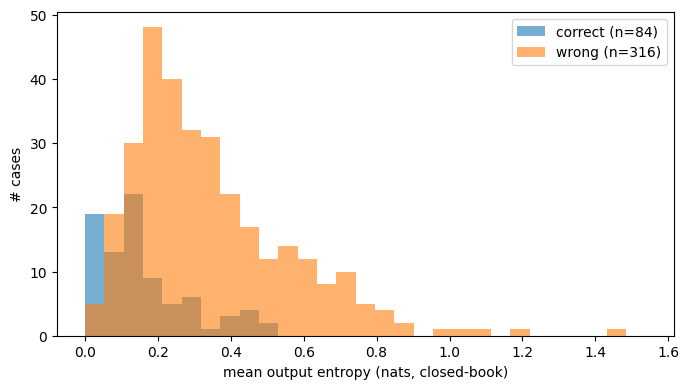

abstain: 16 / 400


In [ ]:
# ===== Cell 6: 토큰 기반 채점 + 분석 =====
import json
import re
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score


# 저장된 raw 결과를 다시 로드
with open(OUT, encoding="utf-8") as f:
    results = [
        json.loads(line)
        for line in f
    ]


_PUNCT_TABLE = str.maketrans({
    char: " "
    for char in ".,!?;:()[]'\"-/"
})

_ARTICLES = {"the", "a", "an"}


def _norm_tokens(text: str) -> list[str]:
    """소문자화, 숫자 쉼표 제거, 문장부호와 관사 제거."""
    text = str(text).lower()

    # 1,000과 1000을 동일하게 처리
    text = re.sub(r"(?<=\d),(?=\d)", "", text)

    text = text.translate(_PUNCT_TABLE)

    return [
        token
        for token in text.split()
        if token not in _ARTICLES
    ]


def _is_subsequence(
    needle: list[str],
    haystack: list[str],
) -> bool:
    """needle이 haystack 안에 연속된 토큰열로 등장하는지 확인."""
    n = len(needle)

    if n == 0:
        return False

    return any(
        haystack[i:i + n] == needle
        for i in range(len(haystack) - n + 1)
    )


def score_answer(
    output: str,
    gold: str,
    aliases: list[str] | None = None,
) -> tuple[bool, str | None]:
    """문자열 substring이 아닌 whole-token 단위 채점."""
    output_tokens = _norm_tokens(output)

    candidates = [gold] + list(aliases or [])

    for candidate in candidates:
        if not candidate:
            continue

        candidate_tokens = _norm_tokens(candidate)

        if _is_subsequence(
            candidate_tokens,
            output_tokens,
        ):
            return True, candidate

    return False, None


# substring 버그 dry-run
dry_tests = [
    ("I do not know the answer.", "K", False),
    ("The element symbol is Fe.", "E", False),
    ("The dog sat on the mat.", "Cat", False),
    ("It is a cat.", "Cat", True),
]

for output, gold, expected in dry_tests:
    actual, _ = score_answer(
        output=output,
        gold=gold,
    )

    assert actual == expected, (
        f"dry-run 실패: output={output}, gold={gold}"
    )

print("토큰 채점기 dry-run 통과")


# 실제 400건 채점
for row in results:
    is_correct, matched = score_answer(
        output=row["prediction"],
        gold=row["gold"],
        aliases=row["aliases"],
    )

    row["is_correct"] = is_correct
    row["matched"] = matched
    row["scoring_version"] = "whole_token_v1"


# scored 파일 저장
SCORED_OUT = "exp6_qwen_scored.jsonl"

with open(SCORED_OUT, "w", encoding="utf-8") as f:
    for row in results:
        f.write(
            json.dumps(
                row,
                ensure_ascii=False,
            ) + "\n"
        )

print("scored 결과 저장:", SCORED_OUT)


def report(rows, label):
    y_true = [
        int(row["is_correct"])
        for row in rows
    ]

    correct = sum(y_true)
    total = len(y_true)

    print(f"\n[{label}] 정답 {correct}/{total}")

    if len(set(y_true)) < 2:
        print("단일 클래스이므로 AUROC 계산 불가")
        return

    metrics = [
        ("mean_entropy", -1),
        ("first_token_entropy", -1),
        ("mean_logprob", 1),
    ]

    for metric, sign in metrics:
        scores = [
            sign * row[metric]
            for row in rows
        ]

        auc = roc_auc_score(
            y_true,
            scores,
        )

        print(f"  {metric}: AUROC={auc:.3f}")


report(results, "전체")

report(
    [
        row
        for row in results
        if not row["is_abstain"]
    ],
    "abstain 제외",
)

report(
    [
        row
        for row in results
        if row["source"].startswith("Warrieryes")
    ],
    "CB만",
)

report(
    [
        row
        for row in results
        if not row["source"].startswith("Warrieryes")
    ],
    "TQA만",
)


correct_entropy = [
    row["mean_entropy"]
    for row in results
    if row["is_correct"]
]

wrong_entropy = [
    row["mean_entropy"]
    for row in results
    if not row["is_correct"]
]

bins = np.linspace(
    0,
    max(row["mean_entropy"] for row in results) + 0.1,
    30,
)

plt.figure(figsize=(7, 4))

plt.hist(
    correct_entropy,
    bins=bins,
    alpha=0.6,
    label=f"correct (n={len(correct_entropy)})",
)

plt.hist(
    wrong_entropy,
    bins=bins,
    alpha=0.6,
    label=f"wrong (n={len(wrong_entropy)})",
)

plt.xlabel("mean output entropy (nats, closed-book)")
plt.ylabel("# cases")
plt.legend()
plt.tight_layout()

FIG_OUT = "fig_entropy_hist_exp6_qwen.png"

plt.savefig(FIG_OUT, dpi=150)
plt.show()

print(
    "abstain:",
    sum(row["is_abstain"] for row in results),
    "/",
    len(results),
)

1. mean_entropy AUROC = 0.790
first_token_entropy는 0.517로 무의미함. mean_logprob는 0.766으로 다음으로 높음.

따라서 **mean_entropy**를 model_knows 라벨링 기준으로 채택하는 것이 좋아보인다! 다영이와 같은 결론이 나옴!

2. CB 정답 13/300 : 예상한 것처럼 TriviaQA가 없었을 경우에 정답을 맞추는 케이스가 매우 적었다.

3. CB vs TQA : 잘 아는 분포에서 지표가 더 잘 작동하는 패턴임. CB만 보면 0.740으로 0.75의 경계선이어서 DPO 라벨링할 때 threshold 근처 케이스를 버퍼 존으로 제외하는 설계가 필요할 것으로 생각됨

4. abstain 0건 : 전체와 abstain 제외 숫자가 완전히 동일. 탐지된 건수가 0이어서, Qwen이 모르면 그럴듯한 이름을 지어냈다거나, abstain 패턴이 영어 표현을 못 잡은 것일 가능성이 있음.

In [ ]:
import random

cb_wrongs = [
    row
    for row in results
    if (
        not row["is_correct"]
        and row["source"].startswith("Warrieryes"))]

sample_size = min(5, len(cb_wrongs))

for row in random.Random(0).sample(
    cb_wrongs,
    sample_size,):
    print("Q:", row["question"])
    print("Gold:", row["gold"])
    print("Prediction:", row["prediction"])
    print("Entropy:", row["mean_entropy"])
    print()

Q: Which educational institution did Anastasios Tsarouchas attend?
Gold: Aristotle University of Thessaloniki
Prediction: Anastasios Tsarouchas attended the National Technical University of Athens.
Entropy: 0.1313493786685956

Q: What position does Pietro Isimbardi currently or formerly hold?
Gold: diocesan bishop
Prediction: I don't have specific information about Pietro Isimbardi's current or former positions. Could you provide more context or details about the field or organization he is associated with?
Entropy: 0.20731649412623593

Q: Which league does Steve Balkun play in?
Gold: NCAA Division I men's basketball
Prediction: Steve Balkun plays in the National Independent Professional Baseball League.
Entropy: 0.3607876950677914

Q: Which country is Big Crazy Family Adventure from?
Gold: United States of America
Prediction: Big Crazy Family Adventure is from the United States.
Entropy: 0.2822291054505761

Q: Which organization, club or musical group is Ubimet a member of?
Gold: Inte

** 두번째 돌렸을 때 내용 **
- CB는 alias가 빈약해서 축약된 표현이 오답으로 처리 된다!! alias 보강하거나 LLM-as-judge 판정을 넣는 것도 좋을 것 같다!

Hallucination과 모른다고 했는데 패턴에 잡히지 않은 케이스가 있음. 즉, 정규식 업데이트 필요  --> 코드 업데이트 하면서 고친 정규식 바로 반영함!

5. abstain 16/400 : Qwen은 모르면 대부분 지어내고 소수만 abstain이 된다.

6. abstain 제외 시 0.790 --> 0.796 : 소폭 상승하게 됨. CB 비중이 큰 실전 라벨링에서는 abstain 필터를 거는게 좋을 것으로 생각됨.

7. mean_entropy를 채택하는 것은 동일한 결과!!

8. DPO 함의: model_knows=true가 CB에서 4.3%뿐이라는 건, 4분면 중 "모델이 앎" 쪽 두 분면의 학습 데이터를 CB만으로 못 채운다는 뜻.

In [ ]:
# ===== Cell 7: meta.json =====
import datetime
import json
import sys
import transformers

meta = {
    "experiment": "exp6_confidence",
    "model": MODEL_ID,
    "model_commit": getattr(
        model.config,
        "_commit_hash",
        None,
    ),
    "dtype": str(DTYPE),
    "gpu": torch.cuda.get_device_name(0),
    "max_new_tokens": MAX_NEW_TOKENS,
    "do_sample": False,
    "seed": 42,
    "dataset_sha256": EXPECTED,
    "n": len(cases),
    "raw_file": OUT,
    "scored_file": SCORED_OUT,
    "scoring_version": "whole_token_v1",
    "transformers": transformers.__version__,
    "torch": torch.__version__,
    "python": sys.version.split()[0],
    "timestamp_utc": datetime.datetime.now(
        datetime.UTC
    ).isoformat(),
}

META_OUT = "exp6_qwen_meta.json"

with open(META_OUT, "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2,)

print(meta)

{'experiment': 'exp6_confidence', 'model': 'Qwen/Qwen2.5-7B-Instruct', 'model_commit': 'a09a35458c702b33eeacc393d103063234e8bc28', 'dtype': 'torch.bfloat16', 'gpu': 'NVIDIA L4', 'max_new_tokens': 64, 'do_sample': False, 'seed': 42, 'dataset_sha256': '963aa84bfb04b5f1fea2295c5e4ff9744e8a287899a0d9eb154c9467c92ac920', 'n': 400, 'raw_file': 'exp6_qwen_raw.jsonl', 'scored_file': 'exp6_qwen_scored.jsonl', 'scoring_version': 'whole_token_v1', 'transformers': '5.12.1', 'torch': '2.11.0+cu128', 'python': '3.12.13', 'timestamp_utc': '2026-07-15T09:05:05.683573+00:00'}


### Mistral _ exp6

In [ ]:
# ===== Cell 1: 환경 =====
!pip -q install "transformers==4.53.0" accelerate scikit-learn

!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 123.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 49.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 110.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.19.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.
NVIDIA L4, 23034 MiB


In [ ]:
# ===== Cell 2: 데이터 (리포에서, 해시 검증) =====
!git clone -q https://github.com/Ontology0/Graduation-Project.git
import hashlib, json
P = "Graduation-Project/experiments/main_2026-07-11/shared_data/exp6_questions_n400_seed42.jsonl"
EXPECTED = "963aa84bfb04b5f1fea2295c5e4ff9744e8a287899a0d9eb154c9467c92ac920"
assert hashlib.sha256(open(P,"rb").read()).hexdigest() == EXPECTED, "데이터 버전 불일치!"
cases = [json.loads(l) for l in open(P, encoding="utf-8")]
print("데이터 검증 OK:", len(cases), "건")

데이터 검증 OK: 400 건


In [ ]:
# ===== Cell 3: 모델 =====
import torch, numpy as np
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
set_seed(42)

MODEL_ID = "mistralai/Mistral-7B-Instruct-v0.3"
DTYPE = torch.bfloat16
MAX_NEW_TOKENS = 64

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map="auto")
model.eval()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/587k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

...

model-00003-of-00003.safetensors:   0%|          | 0.00/4.55G [00:00<?, ?B/s]

model-00002-of-00003.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

MistralForCausalLM(
  (model): MistralModel(
    (embed_tokens): Embedding(32768, 4096)
    (layers): ModuleList(
      (0-31): 32 x MistralDecoderLayer(
        (self_attn): MistralAttention(
          (q_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (k_proj): Linear(in_features=4096, out_features=1024, bias=False)
          (v_proj): Linear(in_features=4096, out_features=1024, bias=False)
          (o_proj): Linear(in_features=4096, out_features=4096, bias=False)
        )
        (mlp): MistralMLP(
          (gate_proj): Linear(in_features=4096, out_features=14336, bias=False)
          (up_proj): Linear(in_features=4096, out_features=14336, bias=False)
          (down_proj): Linear(in_features=14336, out_features=4096, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): MistralRMSNorm((4096,), eps=1e-05)
        (post_attention_layernorm): MistralRMSNorm((4096,), eps=1e-05)
      )
    )
    (norm): MistralRMSNorm((4096,), eps=1e-0

In [ ]:
# ===== Cell 4: 추론 함수 =====
@torch.no_grad()
def generate_closed_book(question):
    user = f"Answer the question concisely.\n\nQuestion: {question}"
    inputs = tokenizer.apply_chat_template(
        [{"role":"user","content":user}],
        add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    input_len = inputs["input_ids"].shape[1]

    out = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                         return_dict_in_generate=True, output_scores=True,
                         pad_token_id=tokenizer.eos_token_id)
    gen_ids = out.sequences[0][input_len:]
    text = tokenizer.decode(gen_ids, skip_special_tokens=True).strip()

    ents, logps = [], []
    for step, logits in enumerate(out.scores):
        p = torch.softmax(logits[0].float(), dim=-1)
        ents.append(-(p * torch.log(p + 1e-12)).sum().item())
        logps.append(torch.log(p[gen_ids[step]] + 1e-12).item())
    return {
        "prediction": text,
        "mean_entropy": float(np.mean(ents)) if ents else 0.0,
        "first_token_entropy": float(ents[0]) if ents else 0.0,
        "mean_logprob": float(np.mean(logps)) if logps else 0.0,
        "n_tokens": len(ents),
    }

In [ ]:
# ===== Cell 5: 실행 및 raw 저장 =====
import re
import json

ABSTAIN_PATTERN = re.compile(
    r"(don'?t know|do not know|not sure|"
    r"no (specific )?information|"
    r"don'?t have (specific |any )?"
    r"(information|details|data)|"
    r"cannot (determine|answer|find|confirm)|"
    r"unable to|couldn'?t find|"
    r"not aware of|no record|"
    r"i'?m sorry|as of my knowledge)",
    re.I,
)

OUT = "exp6_mistral_raw.jsonl"
results = []

for i, case in enumerate(cases):
    generated = generate_closed_book(case["question"])

    row = {
        **{key: case[key]
            for key in [
                "id",
                "question",
                "gold",
                "aliases",
                "source",]},
        **generated,
        "is_abstain": bool(
            ABSTAIN_PATTERN.search(
                generated["prediction"]
            )
        ),
    }

    results.append(row)

    if (i + 1) % 50 == 0 or i == len(cases) - 1:
        with open(OUT, "w", encoding="utf-8") as f:
            for result in results:
                f.write(
                    json.dumps(
                        result,
                        ensure_ascii=False,
                    ) + "\n"
                )

        print(f"[{i + 1}/{len(cases)}] 저장")

print("raw 결과 저장:", OUT)

[50/400] 저장
[100/400] 저장
[150/400] 저장
[200/400] 저장
[250/400] 저장
[300/400] 저장
[350/400] 저장
[400/400] 저장
raw 결과 저장: exp6_mistral_raw.jsonl


토큰 채점기 dry-run 통과
scored 결과 저장: exp6_mistral_scored.jsonl

[전체] 정답 91/400
  mean_entropy: AUROC=0.736
  first_token_entropy: AUROC=0.356
  mean_logprob: AUROC=0.685

[abstain 제외] 정답 91/387
  mean_entropy: AUROC=0.731
  first_token_entropy: AUROC=0.338
  mean_logprob: AUROC=0.679

[CB만] 정답 12/300
  mean_entropy: AUROC=0.737
  first_token_entropy: AUROC=0.532
  mean_logprob: AUROC=0.707

[TQA만] 정답 79/100
  mean_entropy: AUROC=0.602
  first_token_entropy: AUROC=0.572
  mean_logprob: AUROC=0.591


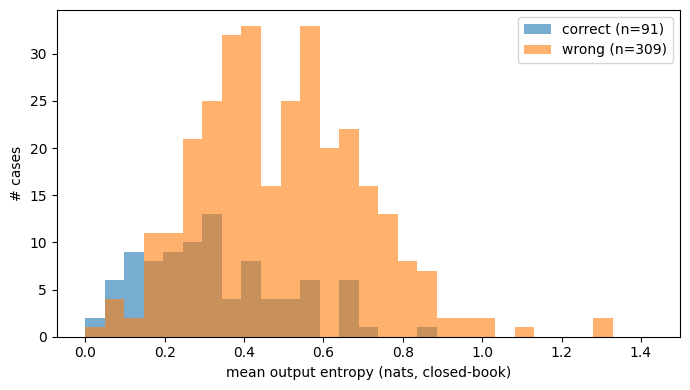

abstain: 13 / 400


In [ ]:
# ===== Cell 6: 토큰 기반 채점 + 분석 =====
import json
import re
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score


# 저장된 raw 결과를 다시 로드
with open(OUT, encoding="utf-8") as f:
    results = [
        json.loads(line)
        for line in f
    ]


_PUNCT_TABLE = str.maketrans({
    char: " "
    for char in ".,!?;:()[]'\"-/"
})

_ARTICLES = {"the", "a", "an"}


def _norm_tokens(text: str) -> list[str]:
    """소문자화, 숫자 쉼표 제거, 문장부호와 관사 제거."""
    text = str(text).lower()

    # 1,000과 1000을 동일하게 처리
    text = re.sub(r"(?<=\d),(?=\d)", "", text)

    text = text.translate(_PUNCT_TABLE)

    return [
        token
        for token in text.split()
        if token not in _ARTICLES
    ]


def _is_subsequence(
    needle: list[str],
    haystack: list[str],
) -> bool:
    """needle이 haystack 안에 연속된 토큰열로 등장하는지 확인."""
    n = len(needle)

    if n == 0:
        return False

    return any(
        haystack[i:i + n] == needle
        for i in range(len(haystack) - n + 1)
    )


def score_answer(
    output: str,
    gold: str,
    aliases: list[str] | None = None,
) -> tuple[bool, str | None]:
    """문자열 substring이 아닌 whole-token 단위 채점."""
    output_tokens = _norm_tokens(output)

    candidates = [gold] + list(aliases or [])

    for candidate in candidates:
        if not candidate:
            continue

        candidate_tokens = _norm_tokens(candidate)

        if _is_subsequence(
            candidate_tokens,
            output_tokens,
        ):
            return True, candidate

    return False, None


# substring 버그 dry-run
dry_tests = [
    ("I do not know the answer.", "K", False),
    ("The element symbol is Fe.", "E", False),
    ("The dog sat on the mat.", "Cat", False),
    ("It is a cat.", "Cat", True),
]

for output, gold, expected in dry_tests:
    actual, _ = score_answer(
        output=output,
        gold=gold,
    )

    assert actual == expected, (
        f"dry-run 실패: output={output}, gold={gold}"
    )

print("토큰 채점기 dry-run 통과")


# 실제 400건 채점
for row in results:
    is_correct, matched = score_answer(
        output=row["prediction"],
        gold=row["gold"],
        aliases=row["aliases"],
    )

    row["is_correct"] = is_correct
    row["matched"] = matched
    row["scoring_version"] = "whole_token_v1"


# scored 파일 저장
SCORED_OUT = "exp6_mistral_scored.jsonl"

with open(SCORED_OUT, "w", encoding="utf-8") as f:
    for row in results:
        f.write(
            json.dumps(
                row,
                ensure_ascii=False,
            ) + "\n"
        )

print("scored 결과 저장:", SCORED_OUT)


def report(rows, label):
    y_true = [
        int(row["is_correct"])
        for row in rows
    ]

    correct = sum(y_true)
    total = len(y_true)

    print(f"\n[{label}] 정답 {correct}/{total}")

    if len(set(y_true)) < 2:
        print("단일 클래스이므로 AUROC 계산 불가")
        return

    metrics = [
        ("mean_entropy", -1),
        ("first_token_entropy", -1),
        ("mean_logprob", 1),
    ]

    for metric, sign in metrics:
        scores = [
            sign * row[metric]
            for row in rows
        ]

        auc = roc_auc_score(
            y_true,
            scores,
        )

        print(f"  {metric}: AUROC={auc:.3f}")


report(results, "전체")

report(
    [
        row
        for row in results
        if not row["is_abstain"]
    ],
    "abstain 제외",
)

report(
    [
        row
        for row in results
        if row["source"].startswith("Warrieryes")
    ],
    "CB만",
)

report(
    [
        row
        for row in results
        if not row["source"].startswith("Warrieryes")
    ],
    "TQA만",
)


correct_entropy = [
    row["mean_entropy"]
    for row in results
    if row["is_correct"]
]

wrong_entropy = [
    row["mean_entropy"]
    for row in results
    if not row["is_correct"]
]

bins = np.linspace(
    0,
    max(row["mean_entropy"] for row in results) + 0.1,
    30,
)

plt.figure(figsize=(7, 4))

plt.hist(
    correct_entropy,
    bins=bins,
    alpha=0.6,
    label=f"correct (n={len(correct_entropy)})",
)

plt.hist(
    wrong_entropy,
    bins=bins,
    alpha=0.6,
    label=f"wrong (n={len(wrong_entropy)})",
)

plt.xlabel("mean output entropy (nats, closed-book)")
plt.ylabel("# cases")
plt.legend()
plt.tight_layout()

FIG_OUT = "fig_entropy_hist_exp6_mistral.png"

plt.savefig(FIG_OUT, dpi=150)
plt.show()

print(
    "abstain:",
    sum(row["is_abstain"] for row in results),
    "/",
    len(results),
)

In [ ]:
# ===== Cell 7: meta.json =====
import datetime
import json
import sys
import transformers

meta = {
    "experiment": "exp6_confidence",
    "model": MODEL_ID,
    "model_commit": getattr(
        model.config,
        "_commit_hash",
        None,
    ),
    "dtype": str(DTYPE),
    "gpu": torch.cuda.get_device_name(0),
    "max_new_tokens": MAX_NEW_TOKENS,
    "do_sample": False,
    "seed": 42,
    "dataset_sha256": EXPECTED,
    "n": len(cases),
    "raw_file": OUT,
    "scored_file": SCORED_OUT,
    "scoring_version": "whole_token_v1",
    "transformers": transformers.__version__,
    "torch": torch.__version__,
    "python": sys.version.split()[0],
    "timestamp_utc": datetime.datetime.now(
        datetime.UTC
    ).isoformat(),
}

META_OUT = "exp6_mistral_meta.json"

with open(META_OUT, "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2,)

print(meta)

{'experiment': 'exp6_confidence', 'model': 'mistralai/Mistral-7B-Instruct-v0.3', 'model_commit': 'c170c708c41dac9275d15a8fff4eca08d52bab71', 'dtype': 'torch.bfloat16', 'gpu': 'NVIDIA L4', 'max_new_tokens': 64, 'do_sample': False, 'seed': 42, 'dataset_sha256': '963aa84bfb04b5f1fea2295c5e4ff9744e8a287899a0d9eb154c9467c92ac920', 'n': 400, 'raw_file': 'exp6_mistral_raw.jsonl', 'scored_file': 'exp6_mistral_scored.jsonl', 'scoring_version': 'whole_token_v1', 'transformers': '4.53.0', 'torch': '2.11.0+cu128', 'python': '3.12.13', 'timestamp_utc': '2026-07-15T07:27:32.785034+00:00'}


## 새로운 벤치마크 _ DynamicQA


https://huggingface.co/datasets/copenlu/dynamicqa

- temporal인데 context가 한 문장 짜리임. 근데 CB는 장문이라서 둘의 길이를 맞추는 조정이 DPO 학습에서 필요할 것으로 보임!  >> 해당 내용이 중요하다고 언급한 연구가 있었는데,, 이름을 까먹음..ㅠ

In [ ]:
# ===== exp7 Step 1: DYNAMICQA temporal 구조 확인 =====
from datasets import load_dataset

ds = load_dataset("copenlu/dynamicqa", "temporal")
print("== splits ==")
print(ds)

split = list(ds.keys())[0]
print("\n== features ==")
print(ds[split].features)

print("\n== 샘플 5건 ==")
for i in range(5):
    r = ds[split][i]
    print(f"[{i}] Q: {r['question']}")
    print(f"    obj: {r['obj']} | replace_name: {r['replace_name']}")
    print(f"    num_edits: {r['num_edits']} | s_pop: {r['s_pop']}")
    print(f"    context: {r['context'][:150]}")
    print()

# num_edits 분포 (volatility 강도)
from collections import Counter
ne = [r["num_edits"] for r in ds[split]]
print("num_edits 분포:", sorted(Counter(ne).items())[:15])
print("총 행수:", len(ds[split]))

README.md:   0%|          | 0.00/2.46k [00:00<?, ?B/s]

temporal.csv:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/2495 [00:00<?, ? examples/s]

== splits ==
DatasetDict({
    test: Dataset({
        features: ['id', 'subj', 'question', 'context', 'obj', 'replace_name', 'num_edits', 's_pop'],
        num_rows: 2495
    })
})

== features ==
{'id': Value('int64'), 'subj': Value('string'), 'question': Value('string'), 'context': Value('string'), 'obj': Value('string'), 'replace_name': Value('string'), 'num_edits': Value('float64'), 's_pop': Value('int64')}

== 샘플 5건 ==
[0] Q: What is George Rankin's occupation?
    obj: politician | replace_name: judge
    num_edits: 4.0 | s_pop: 142
    context:  George James Rankin,  (1 May 1887 – 28 December 1957) was a [ENTITY]. He served in both the House of Representatives and the Senate, representing the

[1] Q: What is John Mayne's occupation?
    obj: journalist | replace_name: literary critic
    num_edits: 3.0 | s_pop: 236
    context:  John Mayne (1759–1836) was a [ENTITY]. In 1780, his poem The Siller Gun appeared in its original form in Ruddiman's Magazine, published by Walter Rud



obj와 replace_name이 정답 vs 오답이 아님. 시점에 따라 둘다 참이었던 값이기 때문에 무조건 오답 처리하면 안된다!! >> 우리에게 필요했던 형식에 벤치마크!!

In [ ]:
from collections import Counter

# 질문 템플릿 분포 (첫 4단어)
templates = Counter(" ".join(r["question"].split()[:4]) for r in ds["test"])
print("질문 템플릿 상위 10:")
for t, c in templates.most_common(10):
    print(f"  {c:5d}  {t}")

# subj 중복 (같은 인물 여러 질문?)
subj_dup = Counter(r["subj"] for r in ds["test"])
print("\nsubj 최다 중복:", subj_dup.most_common(3))
print("고유 subj 수:", len(subj_dup), "/", len(ds['test']))

# obj/replace 동일 케이스 (가짜 conflict 체크, CB 감사에서 배운 것)
same = sum(1 for r in ds["test"] if r["obj"].strip().lower() == r["replace_name"].strip().lower())
print("obj == replace_name:", same)

질문 템플릿 상위 10:
    641  Who was the screenwriter
    442  Who was the producer
     98  Who was the director
     97  Who was the composer
     84  What genre is The
     81  What is the capital
     62  Who is the author
     26  What is the religion
     25  In what country is
     12  Who is the father

subj 최다 중복: [('Pilot', 11), ('Click', 7), ('Taken', 6)]
고유 subj 수: 1992 / 2495
obj == replace_name: 7


In [ ]:
import json, hashlib, random

SEED, N = 42, 400
data = [r for r in ds["test"]
        if r["obj"].strip().lower() != r["replace_name"].strip().lower()]  # 가짜 conflict 7건 제외
print("제외 후:", len(data))

random.Random(SEED).shuffle(data)
picked = data[:N]

out = "exp7_dynamicqa_temporal_n400_seed42.jsonl"
with open(out, "w", encoding="utf-8") as f:
    for i, r in enumerate(picked):
        f.write(json.dumps({
            "id": f"dqa_{i:03d}",
            "source_id": r["id"],
            "question": r["question"].strip(),
            "obj": r["obj"].strip(),                    # 채점 기준 1
            "replace_name": r["replace_name"].strip(),  # 채점 기준 2
            "num_edits": r["num_edits"],
            "s_pop": r["s_pop"],
            "source": "copenlu/dynamicqa temporal test seed42",
        }, ensure_ascii=False) + "\n")

sha = hashlib.sha256(open(out, "rb").read()).hexdigest()
print("파일:", out)
print("sha256:", sha)

# 추출본 num_edits 구간 확인
from collections import Counter
bins = Counter("2" if r["num_edits"]==2 else "3-4" if r["num_edits"]<=4 else "5+"
               for r in picked)
print("num_edits 구간:", dict(bins))
print("\n[샘플 2건]")
for l in open(out, encoding="utf-8").readlines()[:2]:
    print(l.strip())

제외 후: 2488
파일: exp7_dynamicqa_temporal_n400_seed42.jsonl
sha256: fe3a8098643d7a1b4b7dfa7d069a7eebea67e4a10c21090d0a02b7009eb911db
num_edits 구간: {'5+': 62, '3-4': 126, '2': 212}

[샘플 2건]
{"id": "dqa_000", "source_id": 6408042, "question": "What genre is Back to the Future?", "obj": "science fiction film", "replace_name": "action film", "num_edits": 7.0, "s_pop": 150710, "source": "copenlu/dynamicqa temporal test seed42"}
{"id": "dqa_001", "source_id": 1915796, "question": "Who was the producer of Le grand soir?", "obj": "Gustave de Kervern", "replace_name": "Michel Vocoret", "num_edits": 3.0, "s_pop": 286, "source": "copenlu/dynamicqa temporal test seed42"}


In [ ]:
# ===== Cell 2: 데이터 (리포에서, 해시 검증) =====
## 일단 이건 실행 X
!git clone -q https://github.com/Ontology0/Graduation-Project.git
import hashlib, json
P = "Graduation-Project/experiments/main_2026-07-11/shared_data/exp7_dynamicqa_temporal_n400_seed42.jsonl"
EXPECTED = "fe3a8098643d7a1b4b7dfa7d069a7eebea67e4a10c21090d0a02b7009eb911db"
assert hashlib.sha256(open(P,"rb").read()).hexdigest() == EXPECTED, "데이터 버전 불일치!"
cases = [json.loads(l) for l in open(P, encoding="utf-8")]
print("데이터 검증 OK:", len(cases), "건")

In [ ]:
# ===== Exp7-Qwen Cell 1: 데이터 로드 및 해시 검증 =====
!git clone -q https://github.com/Ontology0/Graduation-Project.git

import hashlib
import json

DATA_PATH = (
    "Graduation-Project/experiments/main_2026-07-11/"
    "shared_data/exp7_dynamicqa_temporal_n400_seed42.jsonl"
)

EXP7_DATASET_SHA256 = (
    "fe3a8098643d7a1b4b7dfa7d069a7eeb"
    "ea67e4a10c21090d0a02b7009eb911db"
)

actual_hash = hashlib.sha256(
    open(DATA_PATH, "rb").read()
).hexdigest()

assert actual_hash == EXP7_DATASET_SHA256, (
    f"데이터 버전 불일치!\n"
    f"expected: {EXP7_DATASET_SHA256}\n"
    f"actual:   {actual_hash}"
)

with open(DATA_PATH, encoding="utf-8") as f:
    cases = [json.loads(line) for line in f]

assert len(cases) == 400

print("데이터 검증 OK:", len(cases), "건")
print("필드:", cases[0].keys())

데이터 검증 OK: 400 건
필드: dict_keys(['id', 'source_id', 'question', 'obj', 'replace_name', 'num_edits', 's_pop', 'source'])


In [ ]:
# ===== Cell 3: 모델 =====
import torch, numpy as np
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
set_seed(42)

MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
MODEL_TAG = "qwen25_7b"
DTYPE = torch.bfloat16
MAX_NEW_TOKENS = 64

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map="auto")
model.eval()

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(152064, 3584)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=3584, out_features=3584, bias=True)
          (k_proj): Linear(in_features=3584, out_features=512, bias=True)
          (v_proj): Linear(in_features=3584, out_features=512, bias=True)
          (o_proj): Linear(in_features=3584, out_features=3584, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=3584, out_features=18944, bias=False)
          (up_proj): Linear(in_features=3584, out_features=18944, bias=False)
          (down_proj): Linear(in_features=18944, out_features=3584, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((3584,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((3584,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((3584,), eps=1e-06)
    (ro

In [ ]:
# ===== Cell 4: 추론 함수 =====
@torch.no_grad()
def generate_closed_book(question):
    user = f"Answer the question concisely.\n\nQuestion: {question}"
    inputs = tokenizer.apply_chat_template(
        [{"role":"user","content":user}],
        add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    input_len = inputs["input_ids"].shape[1]

    out = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                         return_dict_in_generate=True, output_scores=True,
                         pad_token_id=tokenizer.eos_token_id)
    gen_ids = out.sequences[0][input_len:]
    prediction = tokenizer.decode(gen_ids, skip_special_tokens=True).strip()

    entropies, logps = [], []
    for step, logits in enumerate(out.scores):
        p = torch.softmax(logits[0].float(), dim=-1)
        entropies.append(-(p * torch.log(p + 1e-12)).sum().item())
        logps.append(torch.log(p[gen_ids[step]] + 1e-12).item())
    return {
        "prediction": prediction,
        "mean_entropy": float(np.mean(entropies)) if entropies else 0.0,
        "first_token_entropy": float(entropies[0]) if entropies else 0.0,
        "mean_logprob": float(np.mean(logps)) if logps else 0.0,
        "n_tokens": len(entropies),
    }

In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("model device:", next(model.parameters()).device)
!nvidia-smi --query-gpu=name,memory.used,utilization.gpu --format=csv,noheader

CUDA available: True
model device: cuda:0
NVIDIA L4, 14740 MiB, 0 %


In [ ]:
print(model.hf_device_map)

AttributeError: 'Qwen2ForCausalLM' object has no attribute 'hf_device_map'

In [ ]:
# ===== Exp7-Qwen Cell 4: 400건 실행 및 raw 저장 =====
import json
import re

ABSTAIN_PATTERN = re.compile(
    r"(don'?t know|do not know|not sure|"
    r"no (specific )?information|"
    r"don'?t have (specific |any )?"
    r"(information|details|data)|"
    r"cannot (determine|answer|find|confirm)|"
    r"unable to|couldn'?t find|"
    r"not aware of|no record|"
    r"i'?m sorry|as of my knowledge)",
    re.I,
)

RAW_OUT = "exp7_qwen_raw.jsonl"
results = []

for i, case in enumerate(cases):
    generated = generate_closed_book(case["question"])
    row = {**{key: case[key]
            for key in ["id", "question","obj", "replace_name","num_edits",
                "s_pop","source",]},
        **generated, "is_abstain": bool(ABSTAIN_PATTERN.search(generated["prediction"])),
        "model_id": MODEL_ID,}

    results.append(row)

    if (i + 1) % 50 == 0 or i == len(cases) - 1:
        with open(RAW_OUT, "w", encoding="utf-8") as f:
            for result in results:
                f.write(json.dumps(result,ensure_ascii=False,) + "\n")
        print(f"[{i + 1}/{len(cases)}] 저장")

print("raw 결과 저장:", RAW_OUT)

[50/400] 저장
[100/400] 저장
[150/400] 저장
[200/400] 저장
[250/400] 저장
[300/400] 저장
[350/400] 저장
[400/400] 저장
raw 결과 저장: exp7_qwen_raw.jsonl


scored 결과 저장: exp7_qwen_scored.jsonl
match 결과: Counter({'neither': 323, 'obj_only': 69, 'replace_only': 5, 'both': 3})

[전체] matches_obj: 72/400
  mean_entropy: AUROC=0.810
  first_token_entropy: AUROC=0.600
  mean_logprob: AUROC=0.804

[전체] matches_any: 77/400
  mean_entropy: AUROC=0.813
  first_token_entropy: AUROC=0.608
  mean_logprob: AUROC=0.800

[edits=2] matches_any: 26/212
  mean_entropy: AUROC=0.778
  first_token_entropy: AUROC=0.575
  mean_logprob: AUROC=0.769

[edits=3-4] matches_any: 31/126
  mean_entropy: AUROC=0.816
  first_token_entropy: AUROC=0.581
  mean_logprob: AUROC=0.796

[edits=5+] matches_any: 20/62
  mean_entropy: AUROC=0.808
  first_token_entropy: AUROC=0.670
  mean_logprob: AUROC=0.818

replace_name만 답함: 5/400
abstain: 2 / 400


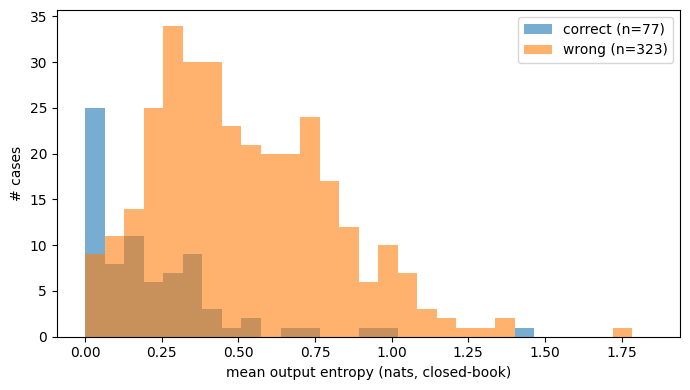

In [ ]:
# ===== Exp7-Qwen Cell 5: 토큰 기반 채점 및 분석 =====
import json
import re

import matplotlib.pyplot as plt
import numpy as np

from collections import Counter
from sklearn.metrics import roc_auc_score


# raw 파일을 다시 읽어서 분석
with open(RAW_OUT, encoding="utf-8") as f:
    results = [json.loads(line)
        for line in f]

assert len(results) == 400, (f"추론 미완료: {len(results)}/400")

assert all(row["model_id"] == MODEL_ID
    for row in results), "다른 모델의 결과가 섞여 있습니다."


_PUNCT_TABLE = str.maketrans({char: " "
    for char in ".,!?;:()[]'\"-/"})

_ARTICLES = {"the", "a", "an"}


def _norm_tokens(text: str) -> list[str]:
    """소문자화, 숫자 쉼표·문장부호·관사 제거."""
    text = str(text).lower()

    # 1,000과 1000을 같게 처리
    text = re.sub(r"(?<=\d),(?=\d)", "", text,)
    text = text.translate(_PUNCT_TABLE)

    return [token for token in text.split()
        if token not in _ARTICLES]


def _is_subsequence(
    needle: list[str],haystack: list[str],) -> bool:
    """needle이 haystack의 연속된 토큰 부분열인지 확인."""
    n = len(needle)

    if n == 0: return False

    return any(haystack[i:i + n] == needle
        for i in range(len(haystack) - n + 1))

def contains_answer(prediction: str,answer: str,) -> bool:
    return _is_subsequence( _norm_tokens(answer),_norm_tokens(prediction),)


# 토큰 매칭
for row in results:
    row["matches_obj"] = contains_answer(prediction=row["prediction"],answer=row["obj"],)

    row["matches_replace"] = contains_answer(prediction=row["prediction"],answer=row["replace_name"],)

    row["matches_any"] = (row["matches_obj"]or row["matches_replace"])

    if ( row["matches_obj"]and row["matches_replace"]):
        row["match_outcome"] = "both"

    elif row["matches_obj"]:
        row["match_outcome"] = "obj_only"

    elif row["matches_replace"]:
        row["match_outcome"] = "replace_only"

    else:row["match_outcome"] = "neither"

    row["scoring_version"] = "whole_token_v1"


SCORED_OUT = "exp7_qwen_scored.jsonl"

with open(SCORED_OUT, "w", encoding="utf-8") as f:
    for row in results:
        f.write(json.dumps(row,ensure_ascii=False,) + "\n")

print("scored 결과 저장:", SCORED_OUT)
print("match 결과:", Counter(row["match_outcome"]for row in results))


def report(rows, label, target_key):
    y_true = [int(row[target_key])for row in rows]

    positives = sum(y_true)
    total = len(y_true)

    print(f"\n[{label}] {target_key}: "f"{positives}/{total}")

    if len(set(y_true)) < 2:
        print("단일 클래스이므로 AUROC 계산 불가")
        return

    metrics = [ ("mean_entropy", -1),("first_token_entropy", -1),("mean_logprob", 1),]

    for metric, sign in metrics:
        scores = [sign * row[metric] for row in rows]

        auc = roc_auc_score(y_true,scores,)
        print(f"  {metric}: AUROC={auc:.3f}")


# 엄격 기준: obj만 정답
report(results,"전체","matches_obj",)

# 관대 기준: obj 또는 replace_name
report(results,"전체","matches_any",)

# num_edits 구간별
for lo, hi, label in [(2, 2, "edits=2"), (3, 4, "edits=3-4"),(5, 99, "edits=5+"),]:
    subset = [row
        for row in results
        if lo <= row["num_edits"] <= hi]

    report(subset,label,"matches_any",)

only_replace = sum(
    row["matches_replace"]
    and not row["matches_obj"]
    for row in results
)

print("\nreplace_name만 답함:",f"{only_replace}/{len(results)}",)

print("abstain:",sum(row["is_abstain"] for row in results),"/",len(results),)


correct_entropy = [
    row["mean_entropy"]
    for row in results
    if row["matches_any"]
]

wrong_entropy = [
    row["mean_entropy"]
    for row in results
    if not row["matches_any"]
]

bins = np.linspace(
    0,max(row["mean_entropy"] for row in results) + 0.1, 30,)

plt.figure(figsize=(7, 4))

plt.hist(correct_entropy,bins=bins,alpha=0.6,label=f"correct (n={len(correct_entropy)})",)

plt.hist(wrong_entropy,bins=bins,alpha=0.6, label=f"wrong (n={len(wrong_entropy)})",)

plt.xlabel("mean output entropy (nats, closed-book)")
plt.ylabel("# cases")
plt.legend()
plt.tight_layout()

FIG_OUT = "fig_entropy_hist_exp7_qwen.png"

plt.savefig(FIG_OUT, dpi=150)
plt.show()

In [ ]:
# ===== Exp7-Qwen Cell 6: meta.json =====
import datetime
import json
import sys

import transformers

meta = {
    "experiment": "exp7_dynamicqa_temporal",
    "model": MODEL_ID,
    "model_tag": MODEL_TAG,
    "model_commit": getattr(
        model.config,
        "_commit_hash",
        None,
    ),
    "dtype": str(DTYPE),
    "gpu": torch.cuda.get_device_name(0),
    "max_new_tokens": MAX_NEW_TOKENS,
    "do_sample": False,
    "seed": 42,
    "dataset_sha256": EXP7_DATASET_SHA256,
    "n": len(cases),
    "raw_file": RAW_OUT,
    "scored_file": SCORED_OUT,
    "figure_file": FIG_OUT,
    "scoring_version": "whole_token_v1",
    "transformers": transformers.__version__,
    "torch": torch.__version__,
    "python": sys.version.split()[0],
    "timestamp_utc": datetime.datetime.now(datetime.UTC).isoformat(),}

META_OUT = "exp7_qwen_meta.json"

with open(META_OUT, "w", encoding="utf-8") as f:
    json.dump(meta,f,ensure_ascii=False,indent=2,)

print(meta)

{'experiment': 'exp7_dynamicqa_temporal', 'model': 'Qwen/Qwen2.5-7B-Instruct', 'model_tag': 'qwen25_7b', 'model_commit': 'a09a35458c702b33eeacc393d103063234e8bc28', 'dtype': 'torch.bfloat16', 'gpu': 'NVIDIA L4', 'max_new_tokens': 64, 'do_sample': False, 'seed': 42, 'dataset_sha256': 'fe3a8098643d7a1b4b7dfa7d069a7eebea67e4a10c21090d0a02b7009eb911db', 'n': 400, 'raw_file': 'exp7_qwen_raw.jsonl', 'scored_file': 'exp7_qwen_scored.jsonl', 'figure_file': 'fig_entropy_hist_exp7_qwen.png', 'scoring_version': 'whole_token_v1', 'transformers': '5.12.1', 'torch': '2.11.0+cu128', 'python': '3.12.13', 'timestamp_utc': '2026-07-15T08:53:33.169988+00:00'}


### Mistral-7B-Instruct-v0.3


In [ ]:
# ===== Exp7-Mistral Cell 1: 데이터 로드 및 해시 검증 =====
!git clone -q https://github.com/Ontology0/Graduation-Project.git

import hashlib
import json

DATA_PATH = (
    "Graduation-Project/experiments/main_2026-07-11/"
    "shared_data/exp7_dynamicqa_temporal_n400_seed42.jsonl"
)

EXP7_DATASET_SHA256 = (
    "fe3a8098643d7a1b4b7dfa7d069a7eeb"
    "ea67e4a10c21090d0a02b7009eb911db"
)

actual_hash = hashlib.sha256(
    open(DATA_PATH, "rb").read()
).hexdigest()

assert actual_hash == EXP7_DATASET_SHA256, (
    f"데이터 버전 불일치!\n"
    f"expected: {EXP7_DATASET_SHA256}\n"
    f"actual:   {actual_hash}"
)

with open(DATA_PATH, encoding="utf-8") as f:
    cases = [json.loads(line) for line in f]

assert len(cases) == 400

print("데이터 검증 OK:", len(cases), "건")
print("필드:", cases[0].keys())

데이터 검증 OK: 400 건
필드: dict_keys(['id', 'source_id', 'question', 'obj', 'replace_name', 'num_edits', 's_pop', 'source'])


In [ ]:
# ===== Exp7-Mistral Cell 2: 모델 =====
import numpy as np
import torch

from transformers import (AutoModelForCausalLM,AutoTokenizer,set_seed,)

set_seed(42)

MODEL_ID = "mistralai/Mistral-7B-Instruct-v0.3"
MODEL_TAG = "mistral7b_v03"

DTYPE = torch.bfloat16
MAX_NEW_TOKENS = 64

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID,)

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map="auto",)

model.eval()

print("모델 로드 완료:", MODEL_ID)
print("모델 device:", model.device)

config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/141k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/587k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

모델 로드 완료: mistralai/Mistral-7B-Instruct-v0.3
모델 device: cuda:0


In [ ]:
# ===== Cell 4: 추론 함수 =====
@torch.no_grad()
def generate_closed_book(question):
    user = f"Answer the question concisely.\n\nQuestion: {question}"
    inputs = tokenizer.apply_chat_template(
        [{"role":"user","content":user}],
        add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    input_len = inputs["input_ids"].shape[1]

    out = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                         return_dict_in_generate=True, output_scores=True,
                         pad_token_id=tokenizer.eos_token_id)
    gen_ids = out.sequences[0][input_len:]
    prediction = tokenizer.decode(gen_ids, skip_special_tokens=True).strip()

    entropies, logps = [], []
    for step, logits in enumerate(out.scores):
        p = torch.softmax(logits[0].float(), dim=-1)
        entropies.append(-(p * torch.log(p + 1e-12)).sum().item())
        logps.append(torch.log(p[gen_ids[step]] + 1e-12).item())
    return {
        "prediction": prediction,
        "mean_entropy": float(np.mean(entropies)) if entropies else 0.0,
        "first_token_entropy": float(entropies[0]) if entropies else 0.0,
        "mean_logprob": float(np.mean(logps)) if logps else 0.0,
        "n_tokens": len(entropies),
    }

In [ ]:
# ===== Cell 5: 실행 (50건마다 중간 저장) =====
import json
import re

ABSTAIN_PATTERN = re.compile(
    r"(don'?t know|do not know|not sure|"
    r"no (specific )?information|"
    r"don'?t have (specific |any )?"
    r"(information|details|data)|"
    r"cannot (determine|answer|find|confirm)|"
    r"unable to|couldn'?t find|"
    r"not aware of|no record|"
    r"i'?m sorry|as of my knowledge)",
    re.I,
)

RAW_OUT = "exp7_mistral_raw.jsonl"
results = []

for i, case in enumerate(cases):
    generated = generate_closed_book(case["question"])
    row = {**{key: case[key]
            for key in ["id", "question","obj", "replace_name","num_edits",
                "s_pop","source",]},
        **generated, "is_abstain": bool(ABSTAIN_PATTERN.search(generated["prediction"])),
        "model_id": MODEL_ID,}

    results.append(row)

    if (i + 1) % 50 == 0 or i == len(cases) - 1:
        with open(RAW_OUT, "w", encoding="utf-8") as f:
            for result in results:
                f.write(json.dumps(result,ensure_ascii=False,) + "\n")
        print(f"[{i + 1}/{len(cases)}] 저장")

print("raw 결과 저장:", RAW_OUT)

[50/400] 저장
[100/400] 저장
[150/400] 저장
[200/400] 저장
[250/400] 저장
[300/400] 저장
[350/400] 저장
[400/400] 저장
raw 결과 저장: exp7_mistral_raw.jsonl


scored 결과 저장: exp7_mistral_scored.jsonl
match 결과: Counter({'neither': 293, 'obj_only': 101, 'both': 4, 'replace_only': 2})

[전체] matches_obj: 105/400
  mean_entropy: AUROC=0.710
  first_token_entropy: AUROC=0.554
  mean_logprob: AUROC=0.691

[전체] matches_any: 107/400
  mean_entropy: AUROC=0.718
  first_token_entropy: AUROC=0.560
  mean_logprob: AUROC=0.699

[edits=2] matches_any: 54/212
  mean_entropy: AUROC=0.768
  first_token_entropy: AUROC=0.553
  mean_logprob: AUROC=0.736

[edits=3-4] matches_any: 35/126
  mean_entropy: AUROC=0.676
  first_token_entropy: AUROC=0.565
  mean_logprob: AUROC=0.676

[edits=5+] matches_any: 18/62
  mean_entropy: AUROC=0.677
  first_token_entropy: AUROC=0.548
  mean_logprob: AUROC=0.658

replace_name만 답함: 2/400
abstain: 0 / 400


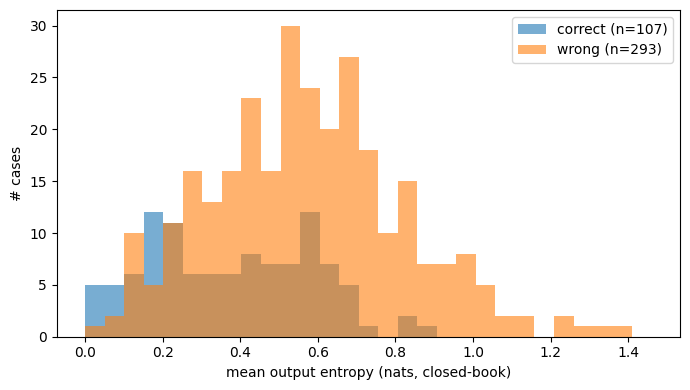

In [ ]:
# ===== Exp7-Mistral Cell 5: 토큰 기반 채점 및 분석 =====
import json
import re

import matplotlib.pyplot as plt
import numpy as np

from collections import Counter
from sklearn.metrics import roc_auc_score


# raw 파일을 다시 읽어서 분석
with open(RAW_OUT, encoding="utf-8") as f:
    results = [json.loads(line)
        for line in f]

assert len(results) == 400, (f"추론 미완료: {len(results)}/400")

assert all(row["model_id"] == MODEL_ID
    for row in results), "다른 모델의 결과가 섞여 있습니다."


_PUNCT_TABLE = str.maketrans({char: " "
    for char in ".,!?;:()[]'\"-/"})

_ARTICLES = {"the", "a", "an"}


def _norm_tokens(text: str) -> list[str]:
    """소문자화, 숫자 쉼표·문장부호·관사 제거."""
    text = str(text).lower()

    # 1,000과 1000을 같게 처리
    text = re.sub(r"(?<=\d),(?=\d)", "", text,)
    text = text.translate(_PUNCT_TABLE)

    return [token for token in text.split()
        if token not in _ARTICLES]


def _is_subsequence(
    needle: list[str],haystack: list[str],) -> bool:
    """needle이 haystack의 연속된 토큰 부분열인지 확인."""
    n = len(needle)

    if n == 0: return False

    return any(haystack[i:i + n] == needle
        for i in range(len(haystack) - n + 1))

def contains_answer(prediction: str,answer: str,) -> bool:
    return _is_subsequence( _norm_tokens(answer),_norm_tokens(prediction),)


# 토큰 매칭
for row in results:
    row["matches_obj"] = contains_answer(prediction=row["prediction"],answer=row["obj"],)

    row["matches_replace"] = contains_answer(prediction=row["prediction"],answer=row["replace_name"],)

    row["matches_any"] = (row["matches_obj"]or row["matches_replace"])

    if ( row["matches_obj"]and row["matches_replace"]):
        row["match_outcome"] = "both"

    elif row["matches_obj"]:
        row["match_outcome"] = "obj_only"

    elif row["matches_replace"]:
        row["match_outcome"] = "replace_only"

    else:row["match_outcome"] = "neither"

    row["scoring_version"] = "whole_token_v1"


SCORED_OUT = "exp7_mistral_scored.jsonl"


with open(SCORED_OUT, "w", encoding="utf-8") as f:
    for row in results:
        f.write(json.dumps(row,ensure_ascii=False,) + "\n")

print("scored 결과 저장:", SCORED_OUT)
print("match 결과:", Counter(row["match_outcome"]for row in results))


def report(rows, label, target_key):
    y_true = [int(row[target_key])for row in rows]

    positives = sum(y_true)
    total = len(y_true)

    print(f"\n[{label}] {target_key}: "f"{positives}/{total}")

    if len(set(y_true)) < 2:
        print("단일 클래스이므로 AUROC 계산 불가")
        return

    metrics = [ ("mean_entropy", -1),("first_token_entropy", -1),("mean_logprob", 1),]

    for metric, sign in metrics:
        scores = [sign * row[metric] for row in rows]

        auc = roc_auc_score(y_true,scores,)
        print(f"  {metric}: AUROC={auc:.3f}")


# 엄격 기준: obj만 정답
report(results,"전체","matches_obj",)

# 관대 기준: obj 또는 replace_name
report(results,"전체","matches_any",)

# num_edits 구간별
for lo, hi, label in [(2, 2, "edits=2"), (3, 4, "edits=3-4"),(5, 99, "edits=5+"),]:
    subset = [row
        for row in results
        if lo <= row["num_edits"] <= hi]

    report(subset,label,"matches_any",)

only_replace = sum(
    row["matches_replace"]
    and not row["matches_obj"]
    for row in results
)

print("\nreplace_name만 답함:",f"{only_replace}/{len(results)}",)

print("abstain:",sum(row["is_abstain"] for row in results),"/",len(results),)


correct_entropy = [
    row["mean_entropy"]
    for row in results
    if row["matches_any"]
]

wrong_entropy = [
    row["mean_entropy"]
    for row in results
    if not row["matches_any"]
]

bins = np.linspace(
    0,max(row["mean_entropy"] for row in results) + 0.1, 30,)

plt.figure(figsize=(7, 4))

plt.hist(correct_entropy,bins=bins,alpha=0.6,label=f"correct (n={len(correct_entropy)})",)

plt.hist(wrong_entropy,bins=bins,alpha=0.6, label=f"wrong (n={len(wrong_entropy)})",)

plt.xlabel("mean output entropy (nats, closed-book)")
plt.ylabel("# cases")
plt.legend()
plt.tight_layout()

FIG_OUT = "fig_entropy_hist_exp7_mistral.png"
plt.savefig(FIG_OUT, dpi=150)
plt.show()

In [ ]:
# ===== Exp7-Mistral Cell 6: meta.json =====
import datetime
import json
import sys

import transformers

meta = {
    "experiment": "exp7_dynamicqa_temporal",
    "model": MODEL_ID,
    "model_tag": MODEL_TAG,
    "model_commit": getattr(
        model.config,
        "_commit_hash",
        None,
    ),
    "dtype": str(DTYPE),
    "gpu": torch.cuda.get_device_name(0),
    "max_new_tokens": MAX_NEW_TOKENS,
    "do_sample": False,
    "seed": 42,
    "dataset_sha256": EXP7_DATASET_SHA256,
    "n": len(cases),
    "raw_file": RAW_OUT,
    "scored_file": SCORED_OUT,
    "figure_file": FIG_OUT,
    "scoring_version": "whole_token_v1",
    "transformers": transformers.__version__,
    "torch": torch.__version__,
    "python": sys.version.split()[0],
    "timestamp_utc": datetime.datetime.now(
        datetime.UTC
    ).isoformat(),
}

META_OUT = "exp7_mistral_meta.json"

with open(META_OUT, "w", encoding="utf-8") as f:
    json.dump(
        meta,
        f,
        ensure_ascii=False,
        indent=2,
    )

print(meta)

{'experiment': 'exp7_dynamicqa_temporal', 'model': 'mistralai/Mistral-7B-Instruct-v0.3', 'model_tag': 'mistral7b_v03', 'model_commit': 'c170c708c41dac9275d15a8fff4eca08d52bab71', 'dtype': 'torch.bfloat16', 'gpu': 'NVIDIA L4', 'max_new_tokens': 64, 'do_sample': False, 'seed': 42, 'dataset_sha256': 'fe3a8098643d7a1b4b7dfa7d069a7eebea67e4a10c21090d0a02b7009eb911db', 'n': 400, 'raw_file': 'exp7_mistral_raw.jsonl', 'scored_file': 'exp7_mistral_scored.jsonl', 'figure_file': 'fig_entropy_hist_exp7_mistral.png', 'scoring_version': 'whole_token_v1', 'transformers': '5.12.1', 'torch': '2.11.0+cu128', 'python': '3.12.13', 'timestamp_utc': '2026-07-12T13:37:24.206101+00:00'}


>> qwen과 Mistral이 서로 다른 결과를 보임

- 정답 : qwen 77/400, Mistral 107/400

- entropy proxy의 유효성이 모델 의존적이다.
- Mistral이 정답은 더 많이 맞췄는데, entropy 분리 측면에서는 더 안 좋은 모습을 보임. 즉 지식량과 calibration이 별개축임을 알 수 있음

- volatility 상호작용이 Mistral에서만 관측됨. Qwen은 전구간에서 균일한 모습을 보이는데, Mistral은 edits=2에서만 AUROC가 통과하고, 고변동 구간에서 무너지는 모습을 보임. >> 이런 경우 어떤 식으로 접근해야 할지?

## Llama-3.1-8B exp7

In [ ]:
from huggingface_hub import login
login()  # HF read 토큰

In [ ]:
# ===== Exp7-Mistral Cell 1: 데이터 로드 및 해시 검증 =====
!git clone -q https://github.com/Ontology0/Graduation-Project.git

import hashlib
import json

DATA_PATH = (
    "Graduation-Project/experiments/main_2026-07-11/"
    "shared_data/exp7_dynamicqa_temporal_n400_seed42.jsonl"
)

EXP7_DATASET_SHA256 = (
    "fe3a8098643d7a1b4b7dfa7d069a7eeb"
    "ea67e4a10c21090d0a02b7009eb911db"
)

actual_hash = hashlib.sha256(
    open(DATA_PATH, "rb").read()
).hexdigest()

assert actual_hash == EXP7_DATASET_SHA256, (
    f"데이터 버전 불일치!\n"
    f"expected: {EXP7_DATASET_SHA256}\n"
    f"actual:   {actual_hash}"
)

with open(DATA_PATH, encoding="utf-8") as f:
    cases = [json.loads(line) for line in f]

assert len(cases) == 400

print("데이터 검증 OK:", len(cases), "건")
print("필드:", cases[0].keys())

데이터 검증 OK: 400 건
필드: dict_keys(['id', 'source_id', 'question', 'obj', 'replace_name', 'num_edits', 's_pop', 'source'])


In [ ]:
# ===== Exp7-Mistral Cell 2: 모델 =====
import numpy as np
import torch

from transformers import (AutoModelForCausalLM,AutoTokenizer,set_seed,)

set_seed(42)

MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct"
MODEL_TAG = "llama_3_1_8B"

DTYPE = torch.bfloat16
MAX_NEW_TOKENS = 64

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID,)

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map="auto",)

model.eval()

print("모델 로드 완료:", MODEL_ID)
print("모델 device:", model.device)

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

모델 로드 완료: meta-llama/Llama-3.1-8B-Instruct
모델 device: cuda:0


In [ ]:
# ===== Cell 4: 추론 함수 =====
@torch.no_grad()
def generate_closed_book(question):
    user = f"Answer the question concisely.\n\nQuestion: {question}"
    inputs = tokenizer.apply_chat_template(
        [{"role":"user","content":user}],
        add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    input_len = inputs["input_ids"].shape[1]

    out = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                         return_dict_in_generate=True, output_scores=True,
                         pad_token_id=tokenizer.eos_token_id)
    gen_ids = out.sequences[0][input_len:]
    prediction = tokenizer.decode(gen_ids, skip_special_tokens=True).strip()

    entropies, logps = [], []
    for step, logits in enumerate(out.scores):
        p = torch.softmax(logits[0].float(), dim=-1)
        entropies.append(-(p * torch.log(p + 1e-12)).sum().item())
        logps.append(torch.log(p[gen_ids[step]] + 1e-12).item())
    return {
        "prediction": prediction,
        "mean_entropy": float(np.mean(entropies)) if entropies else 0.0,
        "first_token_entropy": float(entropies[0]) if entropies else 0.0,
        "mean_logprob": float(np.mean(logps)) if logps else 0.0,
        "n_tokens": len(entropies),
    }

In [ ]:
# ===== Cell 5: 실행 (50건마다 중간 저장) =====
import json
import re

ABSTAIN_PATTERN = re.compile(
    r"(don'?t know|do not know|not sure|"
    r"no (specific )?information|"
    r"don'?t have (specific |any )?"
    r"(information|details|data)|"
    r"cannot (determine|answer|find|confirm)|"
    r"unable to|couldn'?t find|"
    r"not aware of|no record|"
    r"i'?m sorry|as of my knowledge)",
    re.I,
)

RAW_OUT = "exp7_llama_3_1_8B_raw.jsonl"
results = []

for i, case in enumerate(cases):
    generated = generate_closed_book(case["question"])
    row = {**{key: case[key]
            for key in ["id", "question","obj", "replace_name","num_edits",
                "s_pop","source",]},
        **generated, "is_abstain": bool(ABSTAIN_PATTERN.search(generated["prediction"])),
        "model_id": MODEL_ID,}

    results.append(row)

    if (i + 1) % 50 == 0 or i == len(cases) - 1:
        with open(RAW_OUT, "w", encoding="utf-8") as f:
            for result in results:
                f.write(json.dumps(result,ensure_ascii=False,) + "\n")
        print(f"[{i + 1}/{len(cases)}] 저장")

print("raw 결과 저장:", RAW_OUT)

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[50/400] 저장
[100/400] 저장
[150/400] 저장
[200/400] 저장
[250/400] 저장
[300/400] 저장
[350/400] 저장
[400/400] 저장
raw 결과 저장: exp7_llama_3_1_8B_raw.jsonl


scored 결과 저장: exp7_llama_3_1_8B_scored.jsonl
match 결과: Counter({'neither': 286, 'obj_only': 108, 'replace_only': 4, 'both': 2})

[전체] matches_obj: 110/400
  mean_entropy: AUROC=0.746
  first_token_entropy: AUROC=0.623
  mean_logprob: AUROC=0.729

[전체] matches_any: 114/400
  mean_entropy: AUROC=0.755
  first_token_entropy: AUROC=0.624
  mean_logprob: AUROC=0.741

[edits=2] matches_any: 47/212
  mean_entropy: AUROC=0.778
  first_token_entropy: AUROC=0.592
  mean_logprob: AUROC=0.779

[edits=3-4] matches_any: 44/126
  mean_entropy: AUROC=0.740
  first_token_entropy: AUROC=0.614
  mean_logprob: AUROC=0.719

[edits=5+] matches_any: 23/62
  mean_entropy: AUROC=0.674
  first_token_entropy: AUROC=0.685
  mean_logprob: AUROC=0.658

replace_name만 답함: 4/400
abstain: 102 / 400


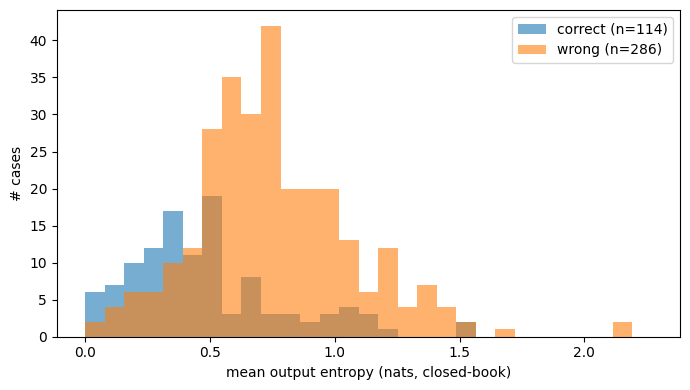

In [ ]:
# ===== Exp7-Mistral Cell 5: 토큰 기반 채점 및 분석 =====
import json
import re

import matplotlib.pyplot as plt
import numpy as np

from collections import Counter
from sklearn.metrics import roc_auc_score


# raw 파일을 다시 읽어서 분석
with open(RAW_OUT, encoding="utf-8") as f:
    results = [json.loads(line)
        for line in f]

assert len(results) == 400, (f"추론 미완료: {len(results)}/400")

assert all(row["model_id"] == MODEL_ID
    for row in results), "다른 모델의 결과가 섞여 있습니다."


_PUNCT_TABLE = str.maketrans({char: " "
    for char in ".,!?;:()[]'\"-/"})

_ARTICLES = {"the", "a", "an"}


def _norm_tokens(text: str) -> list[str]:
    """소문자화, 숫자 쉼표·문장부호·관사 제거."""
    text = str(text).lower()

    # 1,000과 1000을 같게 처리
    text = re.sub(r"(?<=\d),(?=\d)", "", text,)
    text = text.translate(_PUNCT_TABLE)

    return [token for token in text.split()
        if token not in _ARTICLES]


def _is_subsequence(
    needle: list[str],haystack: list[str],) -> bool:
    """needle이 haystack의 연속된 토큰 부분열인지 확인."""
    n = len(needle)

    if n == 0: return False

    return any(haystack[i:i + n] == needle
        for i in range(len(haystack) - n + 1))

def contains_answer(prediction: str,answer: str,) -> bool:
    return _is_subsequence( _norm_tokens(answer),_norm_tokens(prediction),)


# 토큰 매칭
for row in results:
    row["matches_obj"] = contains_answer(prediction=row["prediction"],answer=row["obj"],)

    row["matches_replace"] = contains_answer(prediction=row["prediction"],answer=row["replace_name"],)

    row["matches_any"] = (row["matches_obj"]or row["matches_replace"])

    if ( row["matches_obj"]and row["matches_replace"]):
        row["match_outcome"] = "both"

    elif row["matches_obj"]:
        row["match_outcome"] = "obj_only"

    elif row["matches_replace"]:
        row["match_outcome"] = "replace_only"

    else:row["match_outcome"] = "neither"

    row["scoring_version"] = "whole_token_v1"


SCORED_OUT = "exp7_llama_3_1_8B_scored.jsonl"


with open(SCORED_OUT, "w", encoding="utf-8") as f:
    for row in results:
        f.write(json.dumps(row,ensure_ascii=False,) + "\n")

print("scored 결과 저장:", SCORED_OUT)
print("match 결과:", Counter(row["match_outcome"]for row in results))


def report(rows, label, target_key):
    y_true = [int(row[target_key])for row in rows]

    positives = sum(y_true)
    total = len(y_true)

    print(f"\n[{label}] {target_key}: "f"{positives}/{total}")

    if len(set(y_true)) < 2:
        print("단일 클래스이므로 AUROC 계산 불가")
        return

    metrics = [ ("mean_entropy", -1),("first_token_entropy", -1),("mean_logprob", 1),]

    for metric, sign in metrics:
        scores = [sign * row[metric] for row in rows]

        auc = roc_auc_score(y_true,scores,)
        print(f"  {metric}: AUROC={auc:.3f}")


# 엄격 기준: obj만 정답
report(results,"전체","matches_obj",)

# 관대 기준: obj 또는 replace_name
report(results,"전체","matches_any",)

# num_edits 구간별
for lo, hi, label in [(2, 2, "edits=2"), (3, 4, "edits=3-4"),(5, 99, "edits=5+"),]:
    subset = [row
        for row in results
        if lo <= row["num_edits"] <= hi]

    report(subset,label,"matches_any",)

only_replace = sum(
    row["matches_replace"]
    and not row["matches_obj"]
    for row in results
)

print("\nreplace_name만 답함:",f"{only_replace}/{len(results)}",)

print("abstain:",sum(row["is_abstain"] for row in results),"/",len(results),)


correct_entropy = [
    row["mean_entropy"]
    for row in results
    if row["matches_any"]
]

wrong_entropy = [
    row["mean_entropy"]
    for row in results
    if not row["matches_any"]
]

bins = np.linspace(
    0,max(row["mean_entropy"] for row in results) + 0.1, 30,)

plt.figure(figsize=(7, 4))

plt.hist(correct_entropy,bins=bins,alpha=0.6,label=f"correct (n={len(correct_entropy)})",)

plt.hist(wrong_entropy,bins=bins,alpha=0.6, label=f"wrong (n={len(wrong_entropy)})",)

plt.xlabel("mean output entropy (nats, closed-book)")
plt.ylabel("# cases")
plt.legend()
plt.tight_layout()

FIG_OUT = "fig_entropy_hist_exp7_llama.png"
plt.savefig(FIG_OUT, dpi=150)
plt.show()

In [ ]:
# ===== Exp7-Mistral Cell 6: meta.json =====
import datetime
import json
import sys

import transformers

meta = {
    "experiment": "exp7_dynamicqa_temporal",
    "model": MODEL_ID,
    "model_tag": MODEL_TAG,
    "model_commit": getattr(
        model.config,
        "_commit_hash",
        None,
    ),
    "dtype": str(DTYPE),
    "gpu": torch.cuda.get_device_name(0),
    "max_new_tokens": MAX_NEW_TOKENS,
    "do_sample": False,
    "seed": 42,
    "dataset_sha256": EXP7_DATASET_SHA256,
    "n": len(cases),
    "raw_file": RAW_OUT,
    "scored_file": SCORED_OUT,
    "figure_file": FIG_OUT,
    "scoring_version": "whole_token_v1",
    "transformers": transformers.__version__,
    "torch": torch.__version__,
    "python": sys.version.split()[0],
    "timestamp_utc": datetime.datetime.now(
        datetime.UTC
    ).isoformat(),
}

META_OUT = "exp7_llama_meta.json"

with open(META_OUT, "w", encoding="utf-8") as f:
    json.dump(
        meta,
        f,
        ensure_ascii=False,
        indent=2,
    )

print(meta)

{'experiment': 'exp7_dynamicqa_temporal', 'model': 'meta-llama/Llama-3.1-8B-Instruct', 'model_tag': 'llama_3_1_8B', 'model_commit': '0e9e39f249a16976918f6564b8830bc894c89659', 'dtype': 'torch.bfloat16', 'gpu': 'NVIDIA L4', 'max_new_tokens': 64, 'do_sample': False, 'seed': 42, 'dataset_sha256': 'fe3a8098643d7a1b4b7dfa7d069a7eebea67e4a10c21090d0a02b7009eb911db', 'n': 400, 'raw_file': 'exp7_llama_3_1_8B_raw.jsonl', 'scored_file': 'exp7_llama_3_1_8B_scored.jsonl', 'figure_file': 'fig_entropy_hist_exp7_llama.png', 'scoring_version': 'whole_token_v1', 'transformers': '5.12.1', 'torch': '2.11.0+cu128', 'python': '3.12.13', 'timestamp_utc': '2026-07-15T04:36:23.122676+00:00'}


In [ ]:
ab = [r for r in results if r["is_abstain"]]
nab = [r for r in results if not r["is_abstain"]]
import numpy as np
print(f"abstain 평균 entropy: {np.mean([r['mean_entropy'] for r in ab]):.3f}")
print(f"non-abstain 평균 entropy: {np.mean([r['mean_entropy'] for r in nab]):.3f}")

# abstain 제외 AUROC (핵심)
report(nab, "abstain 제외", "matches_any")
for lo, hi, lab in [(2,2,"edits=2"), (3,4,"edits=3-4"), (5,99,"edits=5+")]:
    sub = [r for r in nab if lo <= r["num_edits"] <= hi]
    report(sub, f"abstain제외/{lab}", "matches_any")

abstain 평균 entropy: 0.809
non-abstain 평균 entropy: 0.634

[abstain 제외] matches_any: 111/298
  mean_entropy: AUROC=0.736
  first_token_entropy: AUROC=0.658
  mean_logprob: AUROC=0.710

[abstain제외/edits=2] matches_any: 45/140
  mean_entropy: AUROC=0.780
  first_token_entropy: AUROC=0.655
  mean_logprob: AUROC=0.763

[abstain제외/edits=3-4] matches_any: 43/100
  mean_entropy: AUROC=0.727
  first_token_entropy: AUROC=0.671
  mean_logprob: AUROC=0.693

[abstain제외/edits=5+] matches_any: 23/58
  mean_entropy: AUROC=0.655
  first_token_entropy: AUROC=0.666
  mean_logprob: AUROC=0.643


### EXP7 최종 결과


1. Volatility 패턴이 3모델 중 2모델에서 나타남
: 라마는 단조 하락, Mistral은 고변동 구간에서 무너짐. **변동 많은 사실 일 수록 entropy가 못 미더워진다**라는 내용이 2/3 모델에서 관측됨. volatility 축을 완전 폐기하면 안 되고, 모델 의존적이며, 고변동 구간에서 라벨링 버퍼 존이 필요할 것으로 생각된다.


2. abstain 102건 _ llama
고엔트로피를 정직하게 회피함. 라마는 모를 때 높은 entropy로 모른다고 말하는 모델임. 즉, abstain 자체를 model_knows = false로 이해할 수 있음. 그래서 abstain 제외시 AUROC가 하락하게 된다.